In [1]:
import xarray as xr
import torch
import numpy as np
import datetime
import cftime
import matplotlib.pyplot as plt
import sys
import re
import matplotlib.colors as colors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean 
import fsspec
import xesmf as xe
from scipy.stats import pearsonr
import os
import cmocean
from functions import *
import warnings
warnings.simplefilter("ignore", category=RuntimeWarning)

%load_ext autoreload
%autoreload 2

In [ ]:

# 5. Variable Mappings
OCEAN_FIELD_NAME_PREFIXES = {
    'thetao': ['thetao_'], 'so': ['so_'], 'uo': ['uo_'], 'vo': ['vo_'],
    'zos': ['zos'], 'sea_surface_temperature': ['sst'], 'lev': ['idepth_']
}

# 6. Plotting Constants
BASINS_TO_PLOT = ['Atlantic', 'Pacific', 'Indian', 'Southern']

DEPTH_SLICES = [
    {'min': 0, 'max': 700, 'title': 'Surface (0-700m)'},
    {'min': 700, 'max': 2000, 'title': 'Intermediate (700-2000m)'},
    {'min': 2000, 'max': 7000, 'title': 'Deep (2000-7000m)'}
]
VAR_CONFIG = {
    'thetao': {'cmap': cmocean.cm.thermal, 'units': '$^\\circ$C', 'label': 'Temperature', 'centered': False},
    'so': {'cmap': cmocean.cm.haline, 'units': 'psu', 'label': 'Salinity', 'centered': False},
    'ohc': {'cmap': cmocean.cm.thermal, 'units': 'J', 'label': 'Total Heat Content', 'centered': False},
    'zos':    {'cmap': cmocean.cm.balance, 'units': 'm',         'label': 'SSH',         'centered': True},
    'uo':     {'cmap': cmocean.cm.balance, 'units': 'm/s',       'label': 'U-Velocity',  'centered': True},
    'vo':     {'cmap': cmocean.cm.balance, 'units': 'm/s',       'label': 'V-Velocity',  'centered': True},
}

# Constants
RHO = 1035          # Reference density (kg/m^3)
CP = 3850           # Specific heat capacity (J/kg/K)
SCALE_FACTOR = 1e21 # Scale to ZJ (10^21 J)


DEPTH_LAYERS = [
    {'title':'2.5m','index':0},
    {'title':'700m','index':10},
    {'title':'2000m','index':14},
    #{'title':'3000m','index':15}
]
# Configuration
BASINS_TO_PLOT = ['Atlantic', 'Pacific', 'Indian', 'Southern']

TIME_INDICES = [0, 300, 580]

In [3]:

# 1. Output Directory (Configurable Name)
OUTPUT_DIR = "Emulator_Evaluation_Figures_1deg_All_New"

my_key = "XL8EJRUDQ7QPDJSUUC8Q"
my_secret = "2HaAeDBeiyGBxeeS60t6iOrrwgW6iebpiqoYkAHM"
fs = fsspec.filesystem("s3", key = my_key, secret = my_secret, client_kwargs={"endpoint_url": "https://nyu1.osn.mghpcc.org"})
storage_options = {"key": my_key, "secret": my_secret, "client_kwargs": {"endpoint_url": "https://nyu1.osn.mghpcc.org"}}


# 2. Emulator Configuration 
# Format: (Path, Label, Color)
# You can add or remove entries here to compare any number of emulators.
EMULATOR_CONFIGS = [
    (
        '/global/homes/y/yy6080/workspace/Ocean_Emulator_Workspace/checkpoints/2026-01-30-samudra_om4_onedeg_20_cap_eval/predictions.zarr',
        "WDMSE-1deg", 
        "tab:orange"
    ),
    (
        '/global/homes/y/yy6080/workspace/Ocean_Emulator_Workspace/checkpoints/2026-02-05-samudra_om4_halfdeg_20_cap_fix_eval/predictions.zarr',
        "WDMSE-1/2deg", 
        "tab:green"
    )
]

# 3. Truth & Aux Paths
TRUTH_CONFIGS = [
    ("/pscratch/sd/y/yy6080/workspace/Ocean_Emulator_Workspace/datasets/onedeg/OM4.zarr", "OM4-1deg"),
    ("/pscratch/sd/y/yy6080/workspace/Ocean_Emulator_Workspace/datasets/halfdeg/OM4.zarr", "OM4-1/2deg"),
]


LEVS_PATH = '/pscratch/sd/a/asubel/Data/Chapter_2/CM4_CMIP_New.zarr/'
OCEAN_SAMPLE_PATH = '/pscratch/sd/a/asubel/full-model/scratch/ocean_sample.nc'
STATIC_GRID_PATH = 's3://emulators/am16581/ocean_static_no_mask_table.zarr'

print(f"Output Directory: {OUTPUT_DIR}")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Load Data
print("Loading Truth Data...")
data_truth_ocean_list = []
for truth_path, truth_label in TRUTH_CONFIGS:
    print(f" - Loading {truth_label} from {truth_path}...")
    if "s3" in truth_path:
        data_truth = xr.open_zarr(truth_path, storage_options=storage_options)
    else:
        data_truth = xr.open_zarr(truth_path)
    data_truth_ocean_list.append(data_truth)

print("Loading Emulators...")
emulators_raw = []
emulator_labels = []
emulator_colors = []

for path, label, color in EMULATOR_CONFIGS:
    try:
        print(f" - Loading {label} from {path}...")
        ds = xr.open_zarr(path).rename({'lat':'y','lon':'x'})
        emulators_raw.append(ds)
        emulator_labels.append(label)
        emulator_colors.append(color)
    except Exception as e:
        print(f"   Error loading {label}: {e}")

if not emulators_raw:
    print("No emulators loaded. Exiting.")

# Sync Time (Assume all emulators align with first emulator, truth aligns with them)
time_slice = slice(emulators_raw[0].time.values[0], emulators_raw[0].time.values[-1])
for i in range(len(data_truth_ocean_list)):
    data_truth_ocean_list[i] = data_truth_ocean_list[i].sel(time=time_slice)

# Load Aux Data
print("Loading Auxiliary Data...")
levs = xr.open_zarr(LEVS_PATH)['lev'].values
ocean_test = xr.open_dataset(OCEAN_SAMPLE_PATH)
depth_levels = concat_levels(ocean_test, 'idepth', 'levels')
dz_from_data = (depth_levels[1:] - depth_levels[:-1]).data

# Load Grid & Generate Masks
shape_processed = (emulators_raw[0].y.size, emulators_raw[0].x.size)
print(f"Loading target grid for shape {shape_processed}...")
target_grid_path = f"s3://emulators/am16581/grids/gaussian_grid_{shape_processed[0]}_by_{shape_processed[1]}.zarr"
target_grid = xr.open_zarr(target_grid_path, storage_options=storage_options)
target_grid_path = f"s3://emulators/am16581/grids/gaussian_grid_{shape_processed[0]}_by_{shape_processed[1]}.zarr"
target_grid = xr.open_zarr(target_grid_path, storage_options=storage_options)
    
target_grid = target_grid.rename({
    "grid_x": "x_b", "grid_y": "y_b", "grid_xt": "x", "grid_yt": "y",
    "grid_lon": "lon_b", "grid_lat": "lat_b", "grid_lont": "lon", "grid_latt": "lat",
}).compute()

print("Regridding basin mask...")
ds_static = xr.open_zarr(STATIC_GRID_PATH, storage_options=storage_options)
ds_source = ds_static[['basin', 'geolat', 'geolon']].rename({'geolat': 'lat', 'geolon': 'lon'})
ds_target = target_grid[['lat', 'lon']]
regridder = xe.Regridder(ds_source, ds_target, method='nearest_s2d', periodic=True, reuse_weights=False)
basin_regridded = regridder(ds_source['basin'])

# Grid Metrics
R = 6.371e6
dx_deg = target_grid['lon_b'].diff('x_b')[:-1].values
dy_deg = target_grid['lat_b'].diff('y_b')[:,:-1].values
dx_cal = np.deg2rad(dx_deg)*np.cos(np.deg2rad(target_grid['lat'].values))*R
dy_cal = np.deg2rad(dy_deg)*R

grid_metrics = {
    'dx': (['y','x'], dx_cal),
    'dy': (['y','x'], dy_cal),
    'areacello': (['y','x'], xe.util.cell_area(target_grid, R).values),
    'basin': (['y','x'], basin_regridded.values) 
}

# # Process Data
# print("Processing Datasets...")
# processed_emulators = []
# processed_truths = []

# for emu_ds in emulators_raw:
#     processed_emulators.append(process_dataset(emu_ds, levs, dz_from_data, grid_metrics))
#     processed_truths.append(process_dataset(data_truth_ocean_list[i], levs, dz_from_data, grid_metrics))

# Process Data
print("Processing Datasets...")
processed_emulators = []
processed_truths = []

for idx, emu_ds in enumerate(emulators_raw):
    # Calculate grid metrics for this resolution's shape
    shape = (emu_ds.y.size, emu_ds.x.size)
    print(f"Processing resolution {shape}...")
    
    target_grid_path = f"s3://emulators/am16581/grids/gaussian_grid_{shape[0]}_by_{shape[1]}.zarr"
    target_grid_res = xr.open_zarr(target_grid_path, storage_options=storage_options)
    target_grid_res = target_grid_res.rename({
        "grid_x": "x_b", "grid_y": "y_b", "grid_xt": "x", "grid_yt": "y",
        "grid_lon": "lon_b", "grid_lat": "lat_b", "grid_lont": "lon", "grid_latt": "lat",
    }).compute()
    
    # Create a NEW regridder for this resolution
    ds_target_res = target_grid_res[['lat', 'lon']]
    regridder_res = xe.Regridder(ds_source, ds_target_res, method='nearest_s2d', periodic=True, reuse_weights=False)
    basin_regridded_res = regridder_res(ds_source['basin'])
    
    dx_deg_res = target_grid_res['lon_b'].diff('x_b')[:-1].values
    dy_deg_res = target_grid_res['lat_b'].diff('y_b')[:,:-1].values
    dx_cal_res = np.deg2rad(dx_deg_res)*np.cos(np.deg2rad(target_grid_res['lat'].values))*R
    dy_cal_res = np.deg2rad(dy_deg_res)*R
    
    grid_metrics_res = {
        'dx': (['y','x'], dx_cal_res),
        'dy': (['y','x'], dy_cal_res),
        'areacello': (['y','x'], xe.util.cell_area(target_grid_res, R).values),
        'basin': (['y','x'], basin_regridded_res.values)  # Use the NEW regridded basin
    }
    
    processed_emulators.append(process_dataset(emu_ds, levs, dz_from_data, grid_metrics_res))
    processed_truths.append(process_dataset(data_truth_ocean_list[idx], levs, dz_from_data, grid_metrics_res))

# Construct Emulator Dictionary
emulators_to_analyze = {}
for i, ds in enumerate(processed_emulators):
    emulators_to_analyze[emulator_labels[i]] = {'ds': ds, 'color': emulator_colors[i],'truth': processed_truths[i],'truth_label': TRUTH_CONFIGS[i][1]}


from functions import extract_basin_masks
masks_list = []
for label, emu_data in emulators_to_analyze.items():
    ds_truth = emu_data['truth']
    masks = extract_basin_masks(ds_truth) 
    masks_list.append(masks)

Output Directory: Emulator_Evaluation_Figures_1deg_All_New
Loading Truth Data...
 - Loading OM4-1deg from /pscratch/sd/y/yy6080/workspace/Ocean_Emulator_Workspace/datasets/onedeg/OM4.zarr...
 - Loading OM4-1/2deg from /pscratch/sd/y/yy6080/workspace/Ocean_Emulator_Workspace/datasets/halfdeg/OM4.zarr...
Loading Emulators...
 - Loading WDMSE-1deg from /global/homes/y/yy6080/workspace/Ocean_Emulator_Workspace/checkpoints/2026-01-30-samudra_om4_onedeg_20_cap_eval/predictions.zarr...
 - Loading WDMSE-1/2deg from /global/homes/y/yy6080/workspace/Ocean_Emulator_Workspace/checkpoints/2026-02-05-samudra_om4_halfdeg_20_cap_fix_eval/predictions.zarr...
Loading Auxiliary Data...
Loading target grid for shape (180, 360)...


Regridding basin mask...
Processing Datasets...
Processing resolution (180, 360)...
Processing resolution (360, 720)...


### Analysis Configuration

**Variables:**
- Primary variable: potential temperature (`thetao`)
- Velocity components: zonal (`uo`) and meridional (`vo`) velocities for kinetic energy analysis

**Vertical Levels:**
- Surface layer (2.5m depth, `lev_idx=0`)
- Mid-depth layer (500m depth, `lev_idx=9`)

**Spatial Domains:**
- **Region 1**: Pacific sector (180°E-243°E, 40°S-35°N)
- **Region 2**: Tropical Pacific (120°E-280°E, 15°S-15°N)

**Temporal Window:** 100 time steps

### Spectral Analyses Performed

For each combination of depth level and spatial region, four complementary spectral analyses are computed:

1. **Isotropic Wavenumber Spectrum (Temperature)**
   - Evaluates spatial scales of temperature variability
   - Target wavenumbers: 0.01, 0.02 cycles/degree

2. **Kinetic Energy Wavenumber Spectrum**
   - Analyzes spatial scales of ocean currents
   - Computed from horizontal velocity components (u, v)
   - Target wavenumbers: 0.01, 0.02 cycles/degree

3. **Temporal Frequency Spectrum (Temperature)**
   - Characterizes timescales of temperature variability
   - Target frequencies: 1.0 cycles/year (interannual), 4.0 cycles/year (seasonal)

4. **Kinetic Energy Temporal Spectrum**
   - Analyzes timescales of current variability
   - Target frequencies: 1.0 cycles/year (interannual), 4.0 cycles/year (seasonal)


=== Evaluating isotropic spectrum at level index 0 for longitude slice(180, 243, None) and latitude slice(-40, 35, None) ===


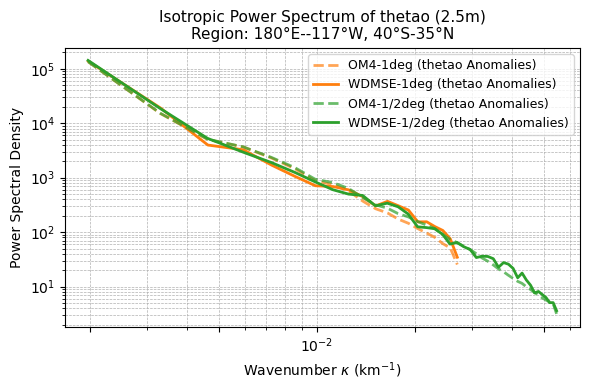


=== Evaluating kinetic energy spectrum at level index 0 for longitude slice(180, 243, None) and latitude slice(-40, 35, None) ===


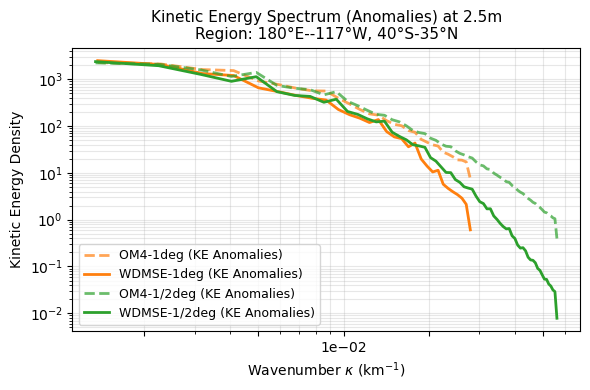


=== Evaluating temporal spectrum at level index 0 for longitude slice(180, 243, None) and latitude slice(-40, 35, None) ===


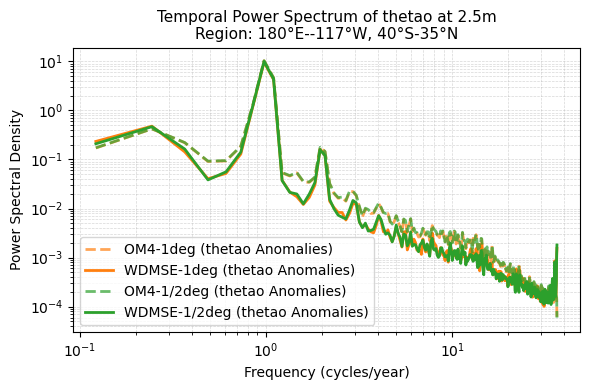


=== Evaluating kinetic energy temporal spectrum at level index 0 for longitude slice(180, 243, None) and latitude slice(-40, 35, None) ===


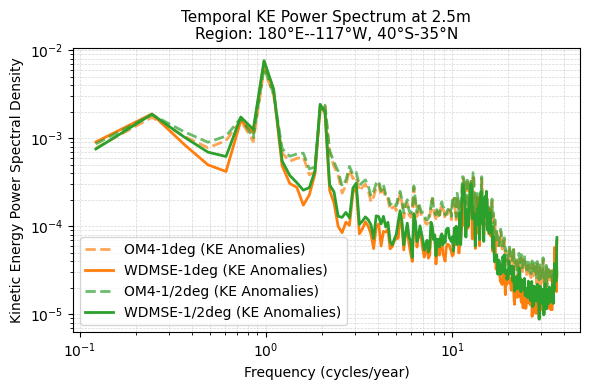


=== Evaluating isotropic spectrum at level index 0 for longitude slice(120, 280, None) and latitude slice(-15, 15, None) ===


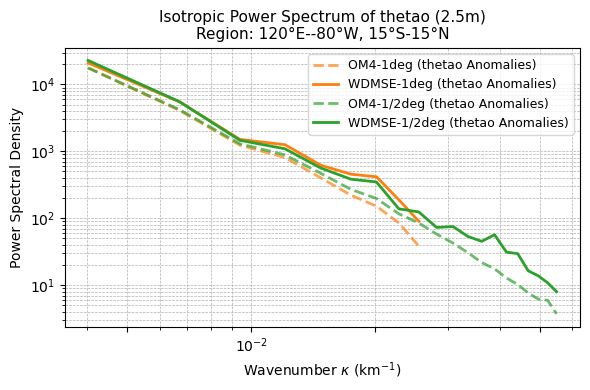


=== Evaluating kinetic energy spectrum at level index 0 for longitude slice(120, 280, None) and latitude slice(-15, 15, None) ===


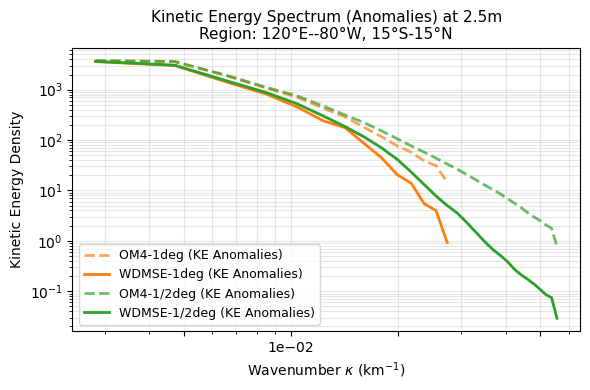


=== Evaluating temporal spectrum at level index 0 for longitude slice(120, 280, None) and latitude slice(-15, 15, None) ===


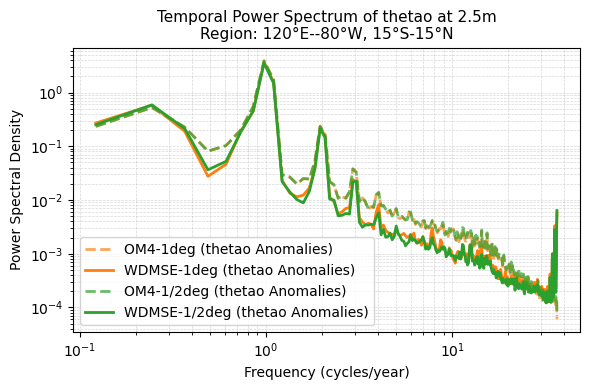


=== Evaluating kinetic energy temporal spectrum at level index 0 for longitude slice(120, 280, None) and latitude slice(-15, 15, None) ===


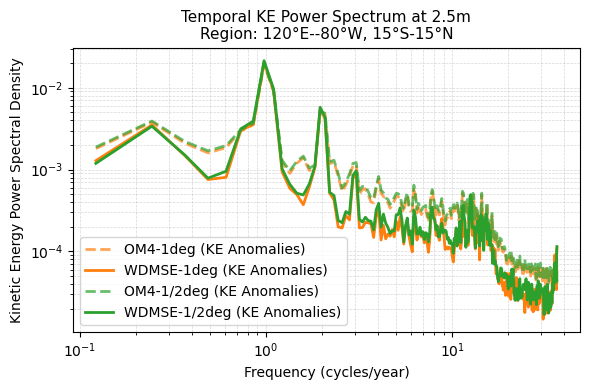


=== Evaluating isotropic spectrum at level index 9 for longitude slice(180, 243, None) and latitude slice(-40, 35, None) ===


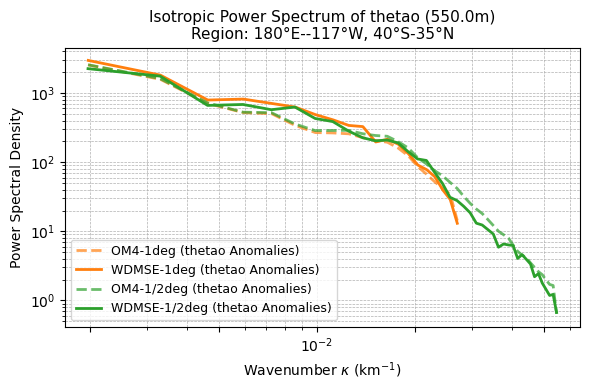


=== Evaluating kinetic energy spectrum at level index 9 for longitude slice(180, 243, None) and latitude slice(-40, 35, None) ===


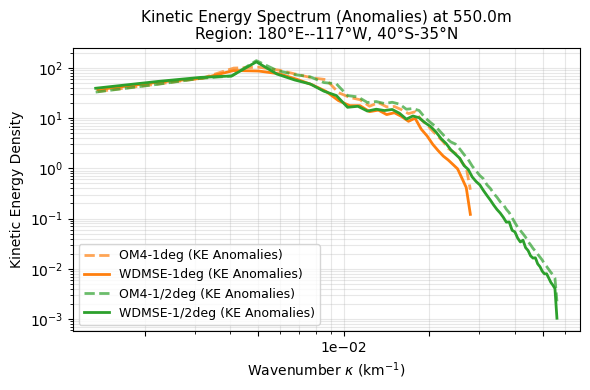


=== Evaluating temporal spectrum at level index 9 for longitude slice(180, 243, None) and latitude slice(-40, 35, None) ===


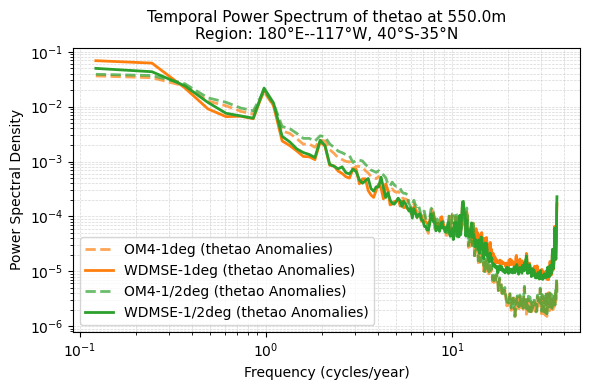


=== Evaluating kinetic energy temporal spectrum at level index 9 for longitude slice(180, 243, None) and latitude slice(-40, 35, None) ===


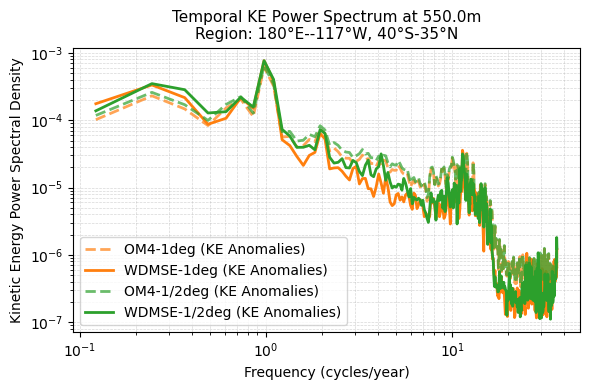


=== Evaluating isotropic spectrum at level index 9 for longitude slice(120, 280, None) and latitude slice(-15, 15, None) ===


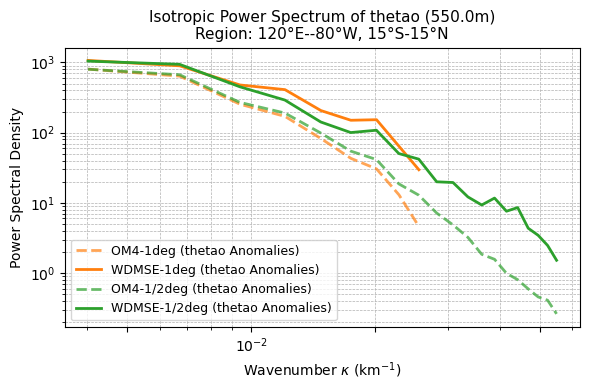


=== Evaluating kinetic energy spectrum at level index 9 for longitude slice(120, 280, None) and latitude slice(-15, 15, None) ===


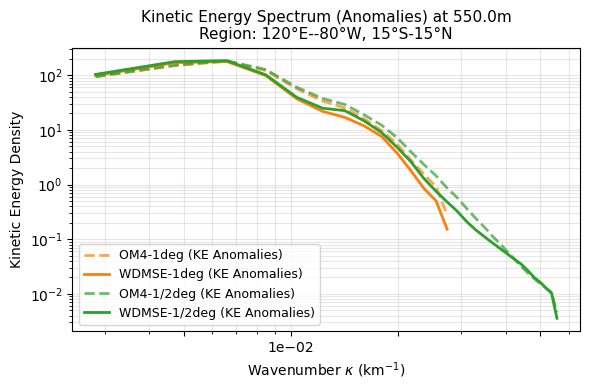


=== Evaluating temporal spectrum at level index 9 for longitude slice(120, 280, None) and latitude slice(-15, 15, None) ===


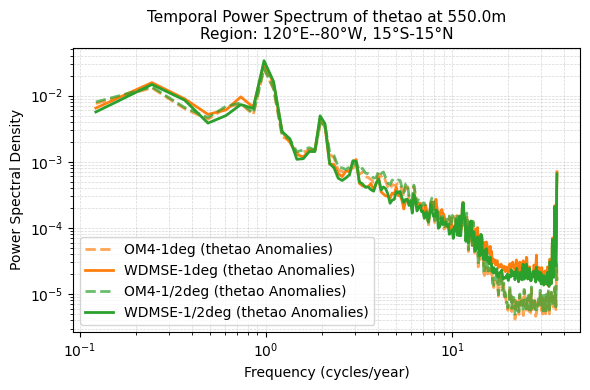


=== Evaluating kinetic energy temporal spectrum at level index 9 for longitude slice(120, 280, None) and latitude slice(-15, 15, None) ===


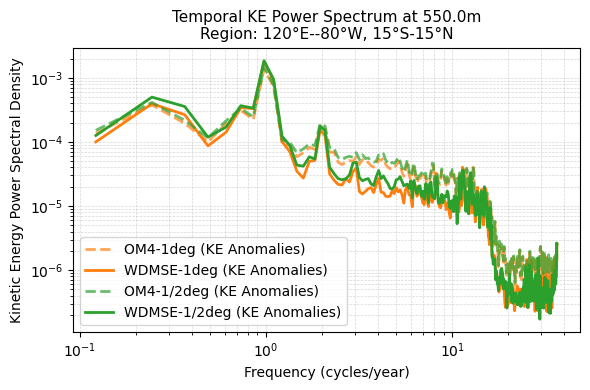

In [10]:
from functions import *
var_to_eval = 'thetao'

time_window = 100

for lev_idx in [0,9]:
    # Call the new function:
    for lon_slice, lat_slice in [(slice(180, 243),slice(-40, 35)), (slice(120,280),slice(-15,15))]:


        print(f"\n=== Evaluating isotropic spectrum at level index {lev_idx} for longitude {lon_slice} and latitude {lat_slice} ===")
        plot_isotropic_spectrum_comparison_together(
            emulators_dict=emulators_to_analyze,
            show_ratios=False,
            var_to_eval=var_to_eval,
            lev_idx=lev_idx,
            time_window=time_window,
            lon_slice=lon_slice,
            lat_slice=lat_slice,
            target_wavenumbers=[0.01, 0.02],
        )

        print(f"\n=== Evaluating kinetic energy spectrum at level index {lev_idx} for longitude {lon_slice} and latitude {lat_slice} ===")
        

        plot_ke_spectrum_comparison_together(
            emulators_dict=emulators_to_analyze,
            show_ratios=False,
            var_u='uo',
            var_v='vo',
            lev_idx=lev_idx,
            time_window=time_window,
            lon_slice=lon_slice,
            lat_slice=lat_slice,
            target_wavenumbers=[0.01, 0.02],
        )

        print(f"\n=== Evaluating temporal spectrum at level index {lev_idx} for longitude {lon_slice} and latitude {lat_slice} ===")

        plot_temporal_spectrum_comparison_together(
            emulators_dict=emulators_to_analyze,
            var_to_eval='thetao',
            show_ratios=False,
            lev_idx=lev_idx,
            lon_slice=lon_slice,
            lat_slice=lat_slice,
            target_frequencies=[1.0, 4.0], 
        )

        print(f"\n=== Evaluating kinetic energy temporal spectrum at level index {lev_idx} for longitude {lon_slice} and latitude {lat_slice} ===")

        plot_ke_temporal_spectrum_comparison_together(
            emulators_dict=emulators_to_analyze,
            show_ratios=False,
            var_u='uo',
            var_v='vo',
            lev_idx=lev_idx,
            lon_slice=lon_slice,
            lat_slice=lat_slice,
            target_frequencies=[1.0, 4.0]
        )

### Time Series of Temperature and Salinity

Global-mean time series of potential temperature (`thetao`) and salinity (`so`), computed over the full evaluation period (2014-2022).

**Settings:**
- **Variables:** `thetao` (temperature, units: °C) and `so` (salinity, units: psu)
- **Depth layers:** Surface (2.5m), 700m, 2000m
- **Averaging:** Global area-weighted mean at each time step
- **Comparison:** Each emulator is plotted against its corresponding OM4 truth


Starting Plotting Sequence...
Generating Time Series for Temperature (Multi-Resolution)...


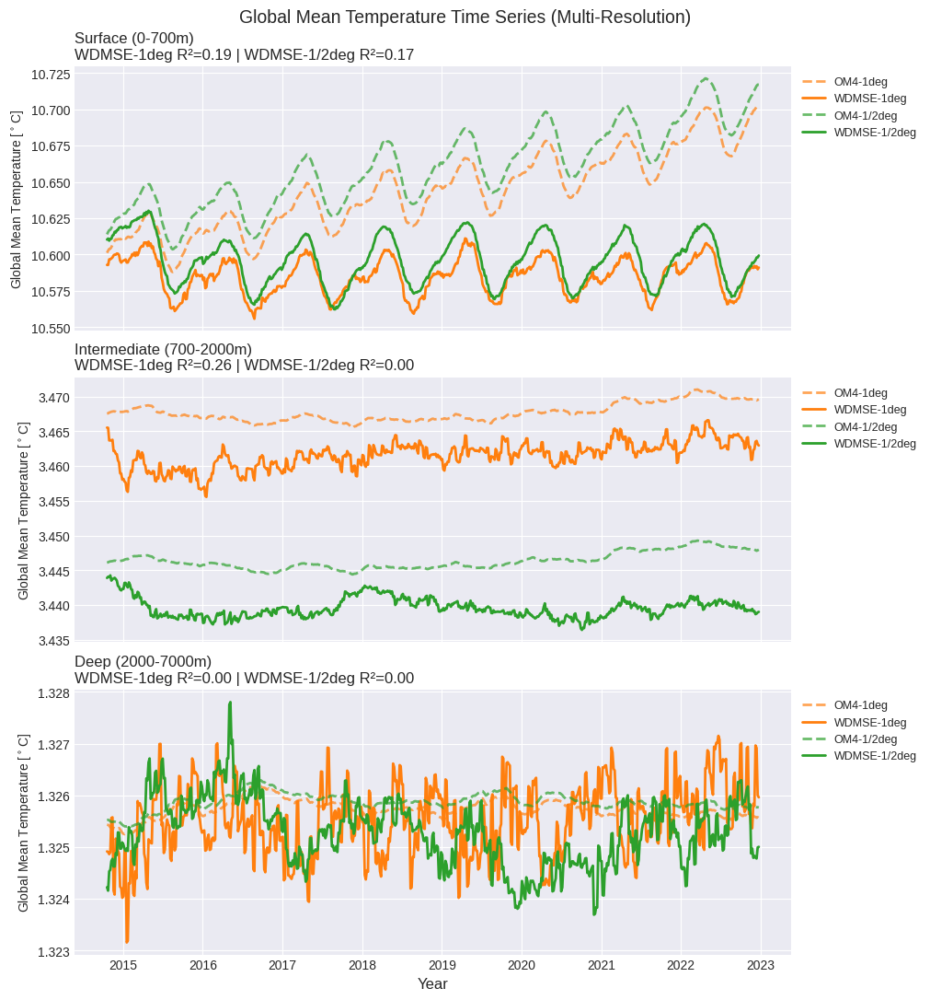

Generating Time Series for Salinity (Multi-Resolution)...


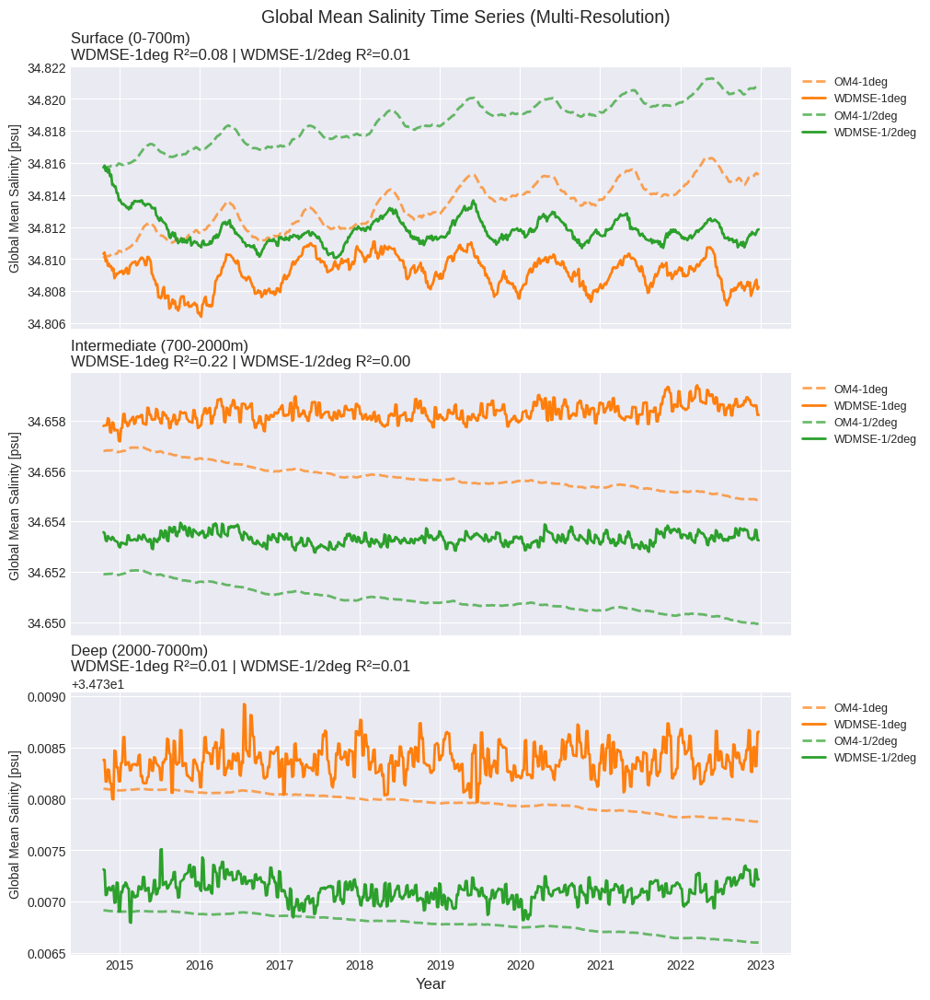

In [4]:

# --- Run Plots ---
print("\nStarting Plotting Sequence...")

from functions import *

# 6. Time Series (Thetao)
plot_mean_timeseries_comparison_together(
    emulators_to_analyze, 
    variable_name='thetao', 
    var_units='$^\\circ$C', 
    var_label='Temperature',
    output_dir=OUTPUT_DIR
)

# 7. Time Series (Salinity)
plot_mean_timeseries_comparison_together(
    emulators_to_analyze, 
    variable_name='so', 
    var_units='psu', 
    var_label='Salinity',
    output_dir=OUTPUT_DIR
)

### Temporal Variance Maps

Spatial maps of temporal variance for temperature and salinity, showing how well the emulators reproduce the variability patterns of the truth data.

**Settings:**
- **Variables:** `thetao` (temperature, units: °C) and `so` (salinity, units: psu)
- **Depth layers:** Surface (2.5m), 700m, 2000m
- **Computation:** Variance computed over the full time dimension at each grid point
- **Colorbar:** Fixed across resolutions for direct comparison


Generating Variance Comparison for thetao (Multi-Resolution)...


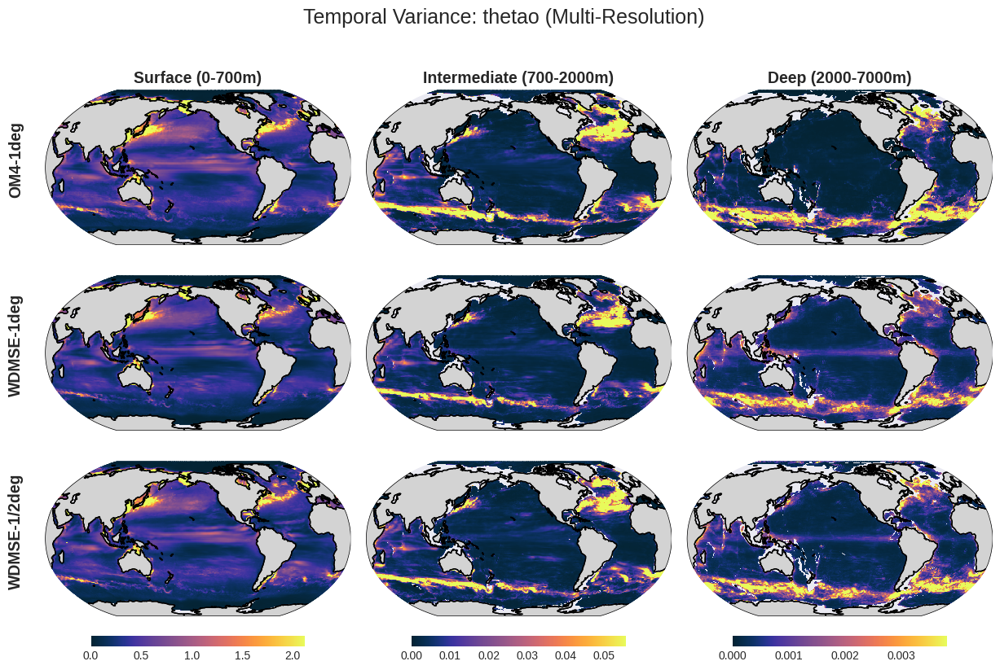


Generating Variance Comparison for so (Multi-Resolution)...


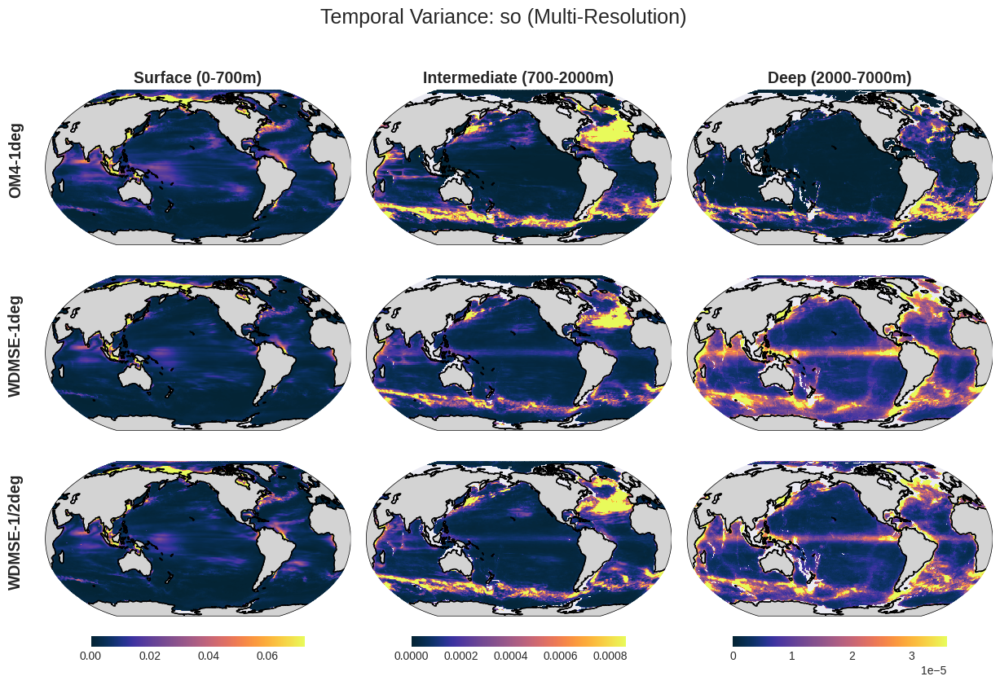

In [5]:
from functions import *

plot_variance_comparison_together(
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\\circ$C',
    output_dir=OUTPUT_DIR,
    colorbar_fix = True
)

plot_variance_comparison_together(
    emulators_to_analyze, 
    variable_name='so',
    units='psu',
    output_dir=OUTPUT_DIR,
    colorbar_fix = True
)    

### Zonal Mean Bias

Zonal-mean bias (emulator minus truth) for temperature and ocean heat content (OHC), shown as latitude-depth cross-sections per ocean basin.

**Settings:**
- **Variables:** `thetao` (temperature, units: °C) and OHC (integrated heat content)
- **Basins:** Atlantic, Pacific, Indian, Southern
- **Views:**
  1. Time-averaged zonal-mean bias over the full evaluation period
  2. Snapshot zonal-mean bias at time indices [0, 300, 580] (start, middle, end)
- **Colorbar:** Fixed across resolutions for direct comparison

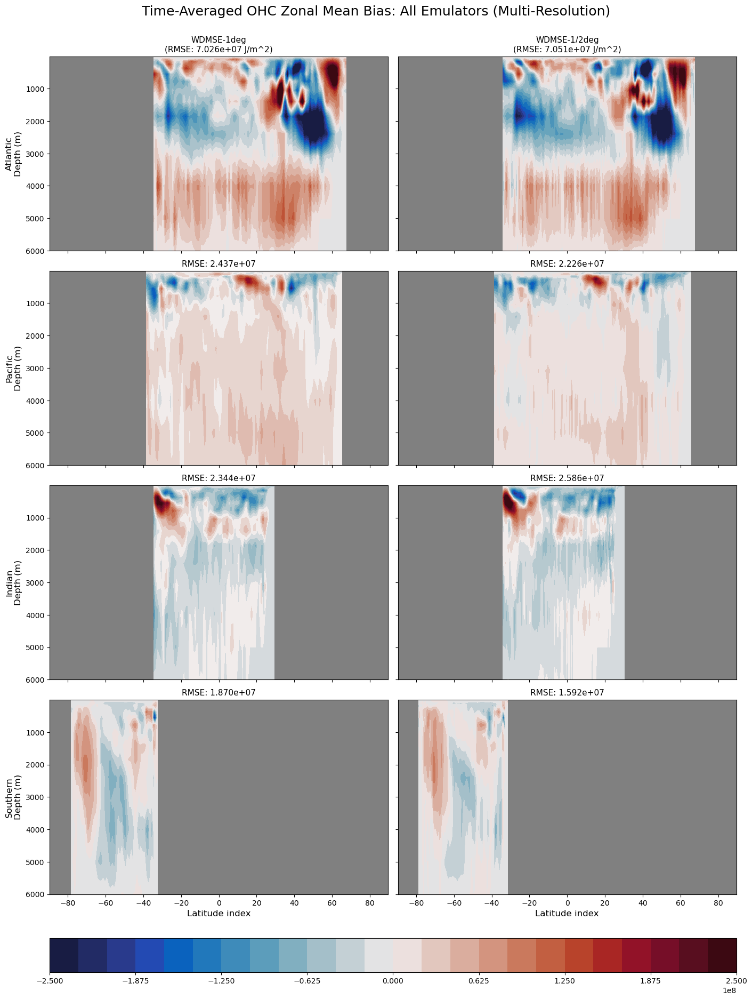

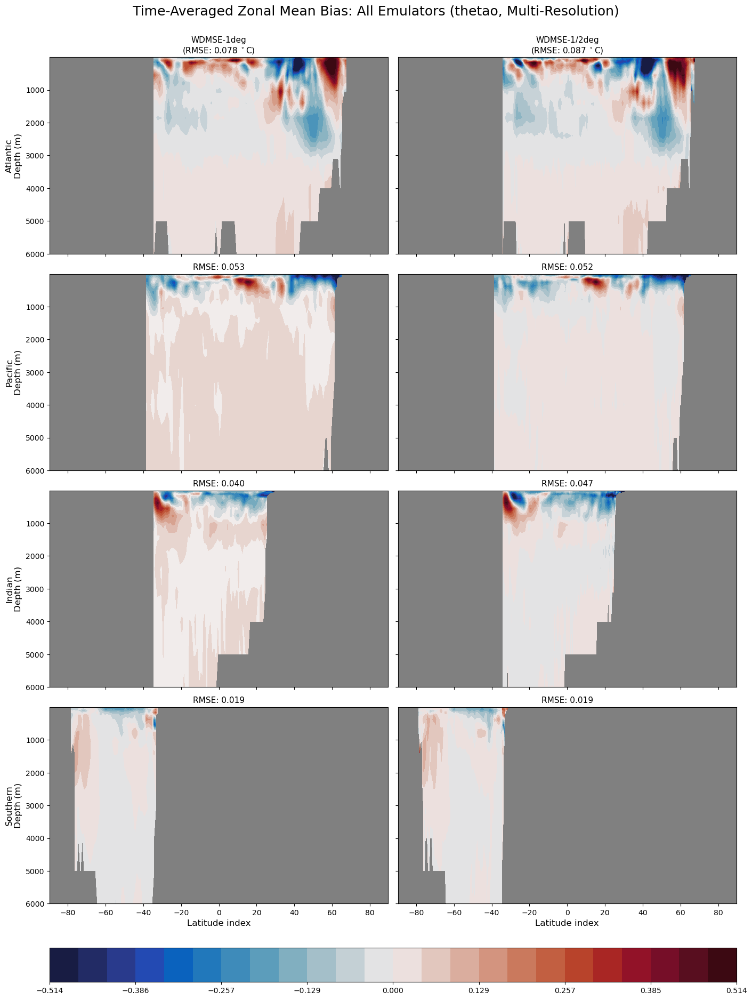

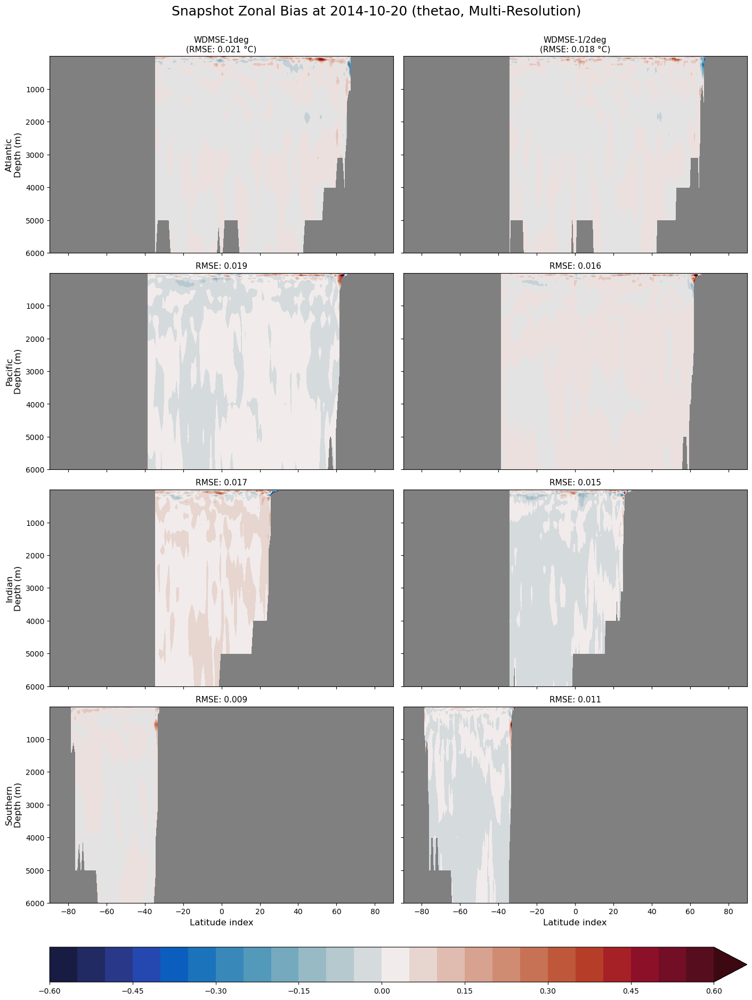

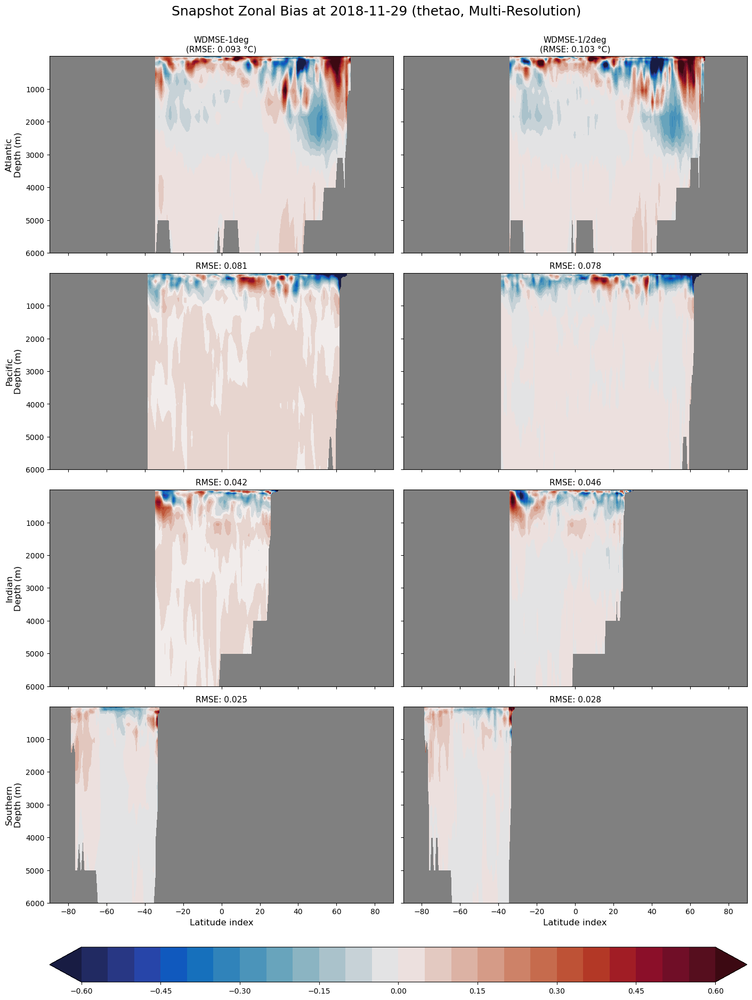

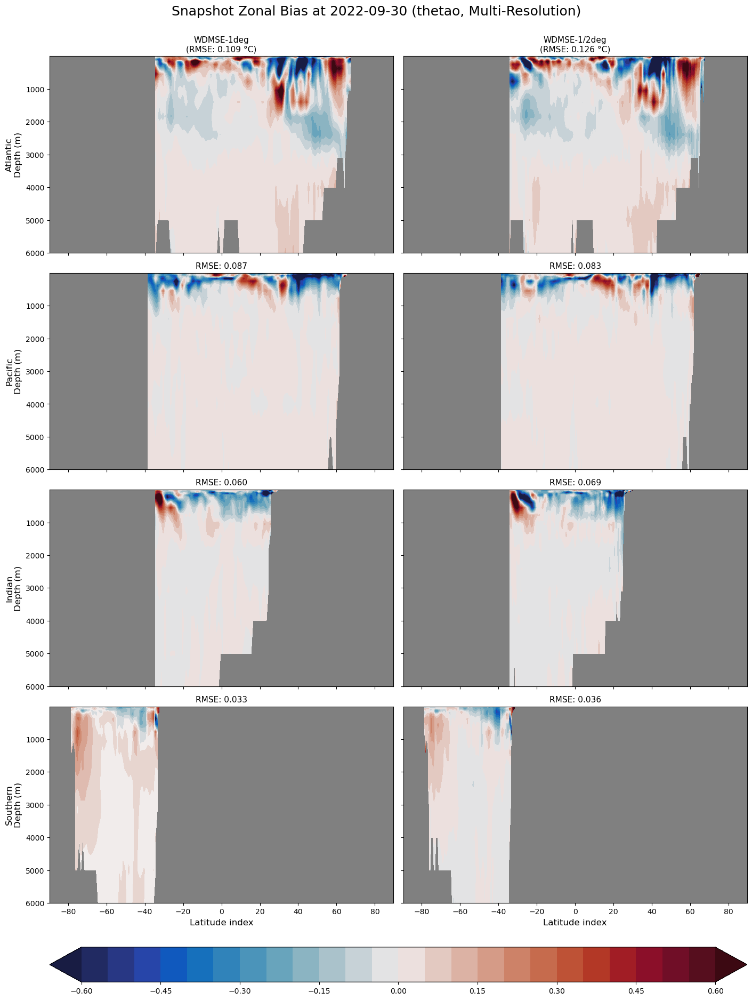

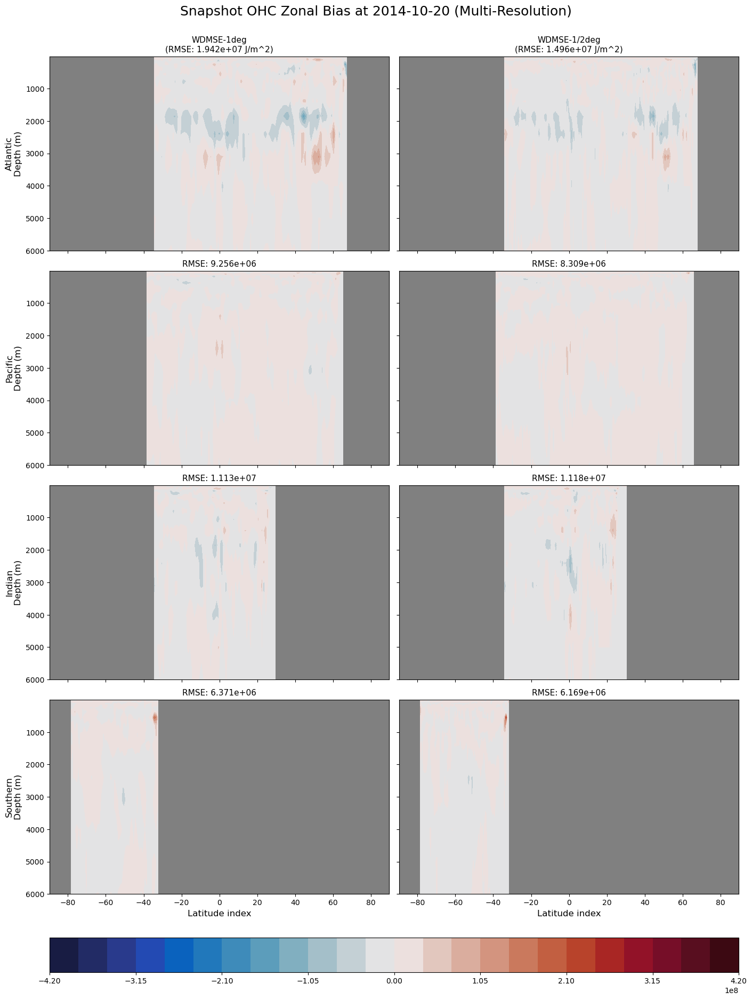

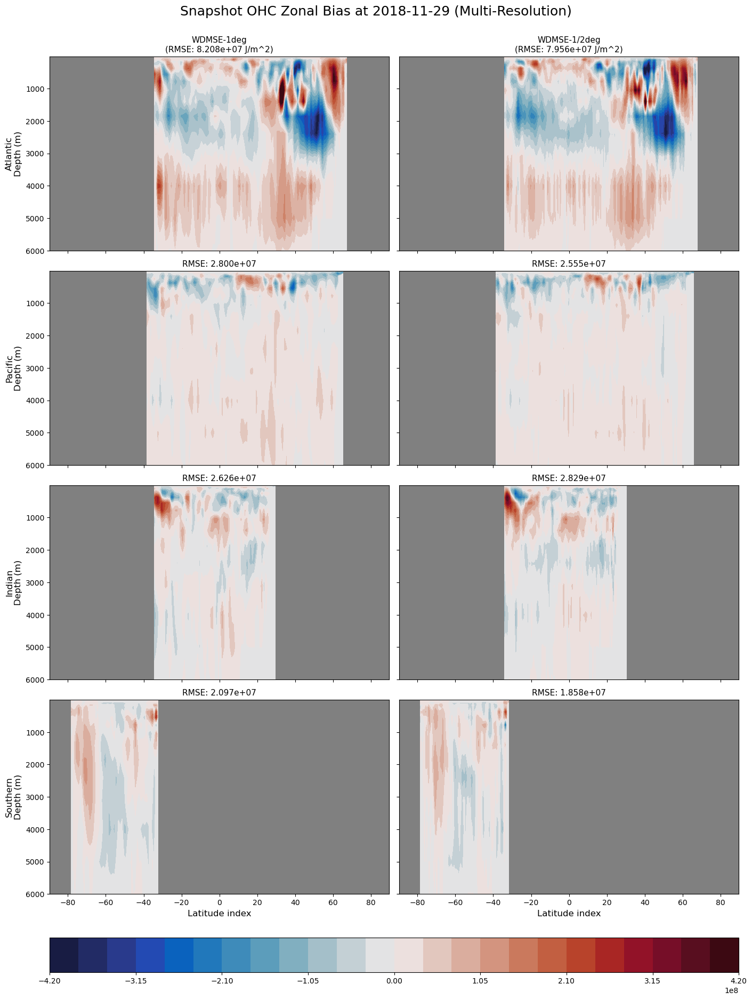

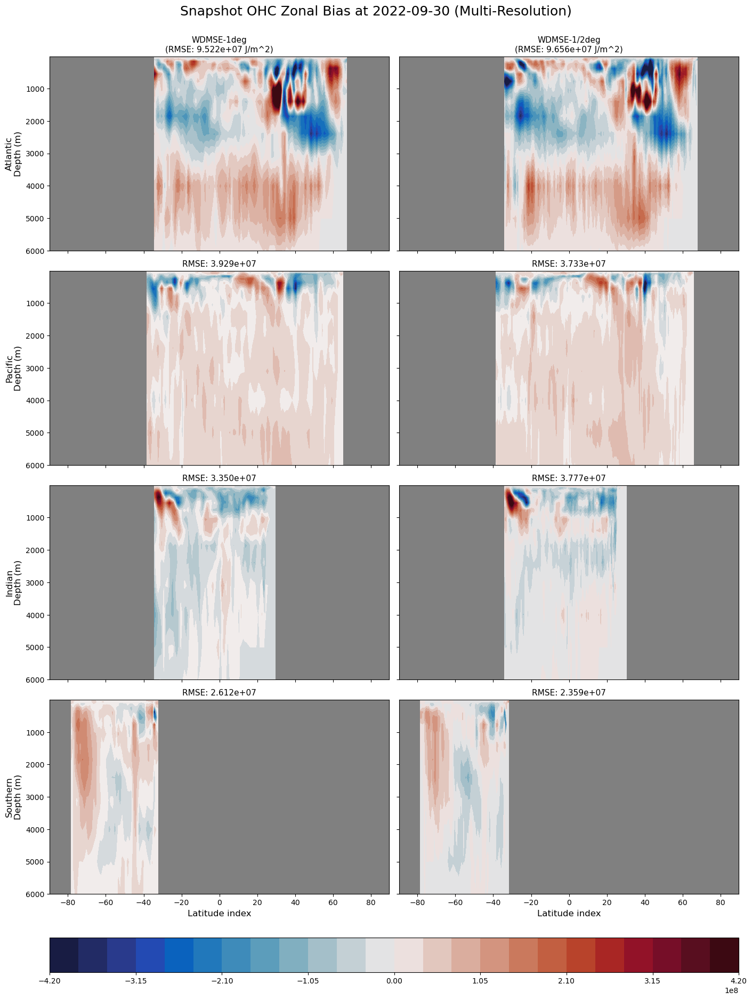

In [4]:
# --- Execution ---

from functions import *

# basin_masks needs to be derived from 2D basin file or sliced
plot_ohc_zonal_bias_ocean_comparison_together(
    emulators_to_analyze, 
    masks_list = masks_list,
    colorbar_fix=True
)

# 1. Zonal Bias (Thetao)
plot_zonal_bias_ocean_comparison_together(
    emulators_to_analyze, 
    'thetao', 
    '$^\\circ$C', 
    masks_list, 
    OUTPUT_DIR,
    colorbar_fix=True
)

plot_snapshot_zonal_bias_ocean_comparison_together(
    emulators_dict=emulators_to_analyze,
    variable_name='thetao',
    units='°C',
    masks_list=masks_list,
    TIME_INDICES=TIME_INDICES,
    colorbar_fix=True
)

plot_snapshot_ohc_zonal_bias_ocean_comparison_together(
    emulators_dict=emulators_to_analyze,
    masks_list=masks_list,
    TIME_INDICES=TIME_INDICES,
    colorbar_fix=True
)

### Global Spatial Bias Maps

Spatial maps of bias (emulator minus truth) for temperature and OHC at selected depth layers.

**Settings:**
- **Variables:** `thetao` (temperature) and OHC
- **Views:**
  1. Time-averaged global bias maps
  2. Snapshot global bias maps at time indices [0, 300, 580] (start, middle, end)
- **Colorbar:** Fixed across resolutions for direct comparison


Generating OHC Bias Comparison (Multi-Resolution)...


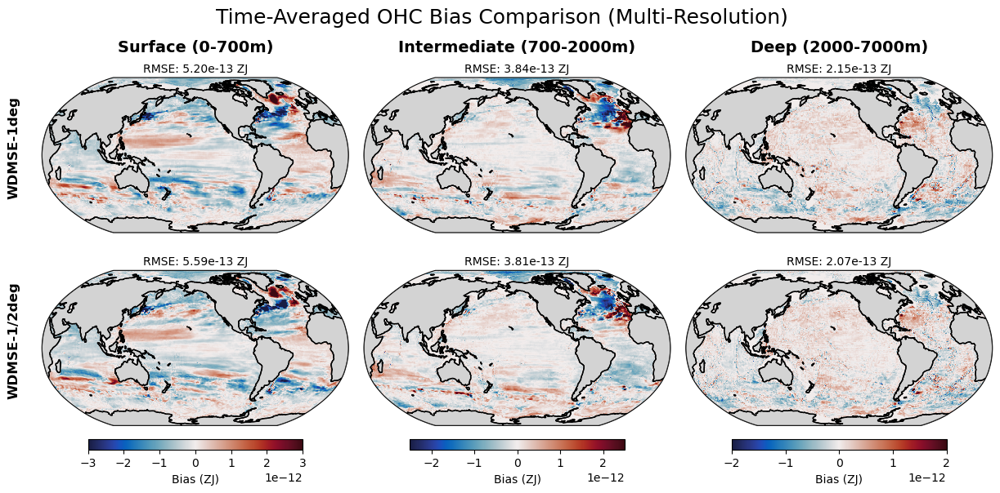


Generating Temperature Bias Comparison (Multi-Resolution)...


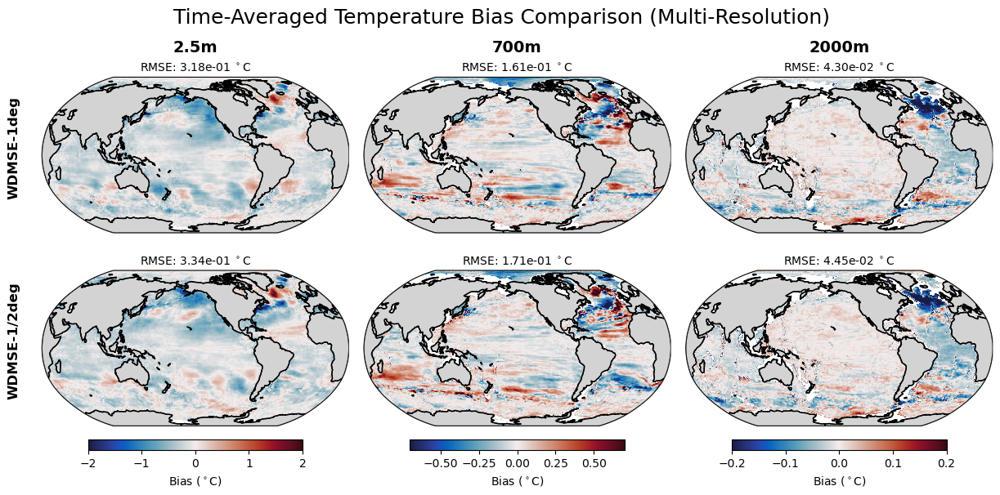

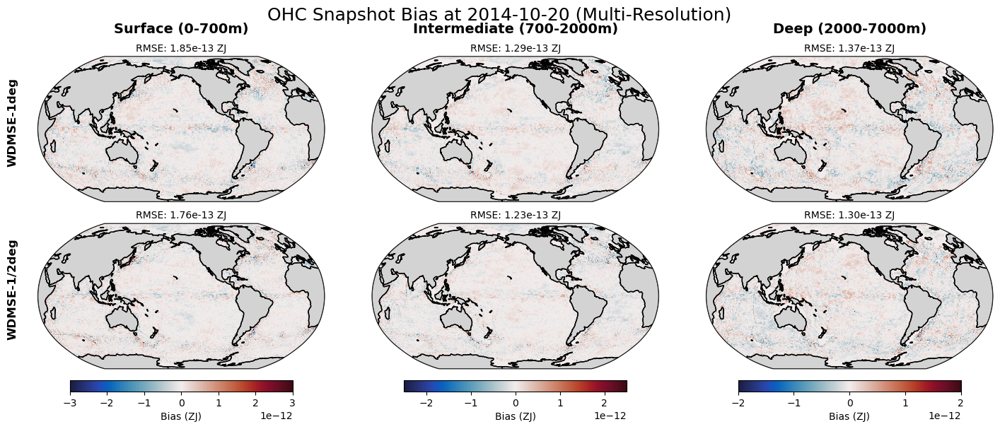

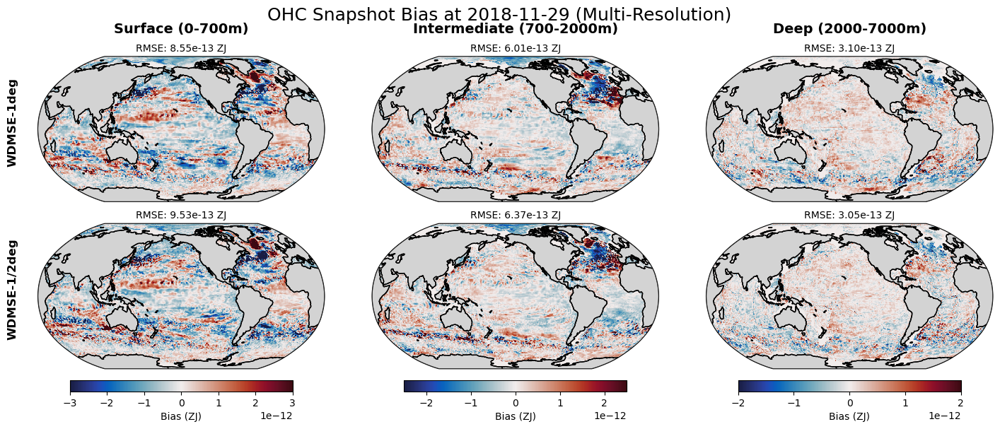

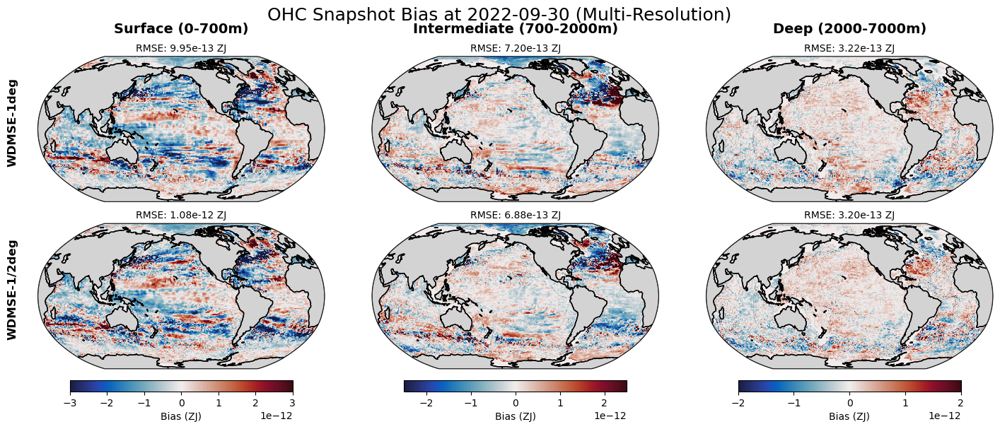

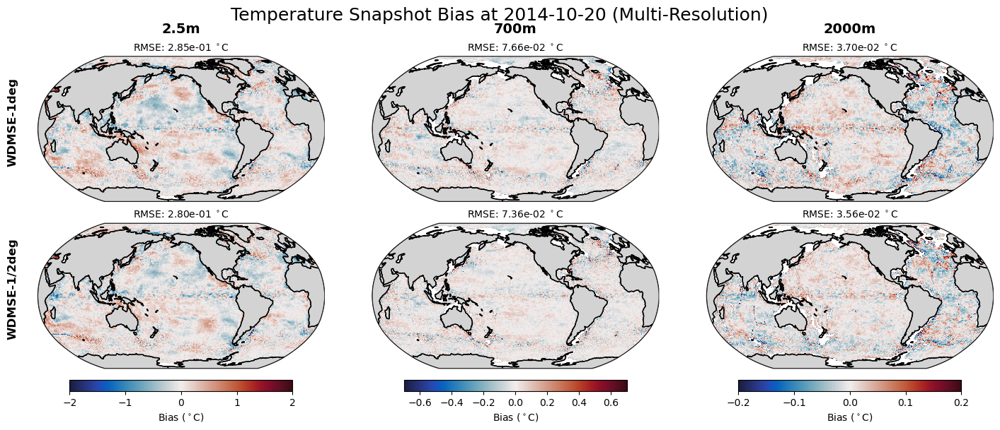

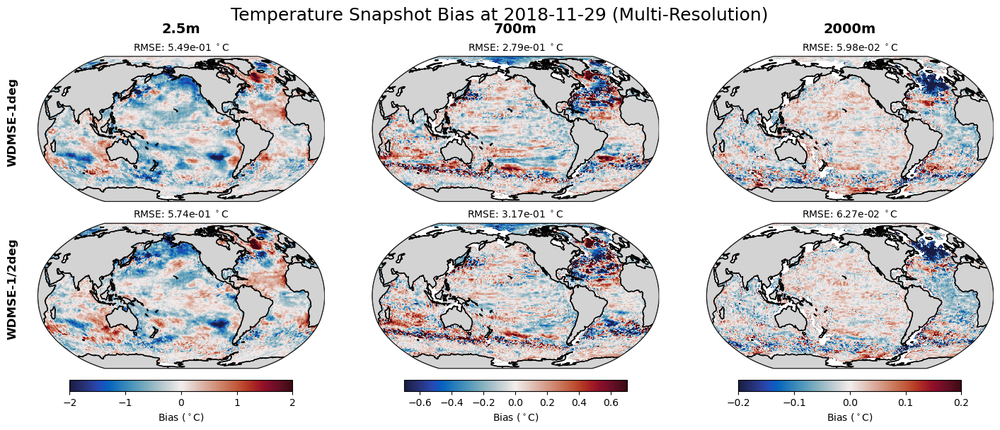

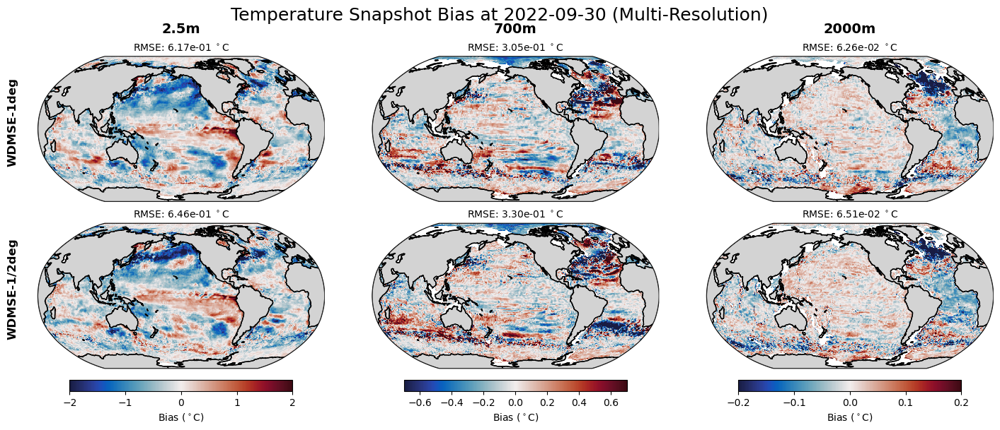

In [6]:
from functions import *

# --- Execution ---
plot_ohc_bias_comparison_together(emulators_to_analyze,colorbar_fix=True)

plot_temperature_bias_comparison_together(emulators_to_analyze,colorbar_fix=True)

plot_ohc_snapshot_bias_comparison_together(emulators_to_analyze, TIME_INDICES, colorbar_fix=True)

plot_temperature_snapshot_bias_comparison_together(emulators_to_analyze, TIME_INDICES, colorbar_fix=True)


### Zonal Mean Distribution

Zonal-mean cross-sections (latitude vs. depth) of temperature and OHC per ocean basin, comparing emulator predictions against truth.

**Settings:**
- **Variables:** `thetao` (temperature, units: °C) and OHC
- **Basins:** Atlantic, Pacific, Indian, Southern
- **Views:**
  1. Time-averaged zonal-mean distribution
  2. Snapshot zonal-mean distribution at time indices [0, 300, 580] (start, middle, end)
- **Colorbar:** Fixed across resolutions for direct comparison


Generating Zonal Mean Comparison for thetao (Multi-Resolution)...


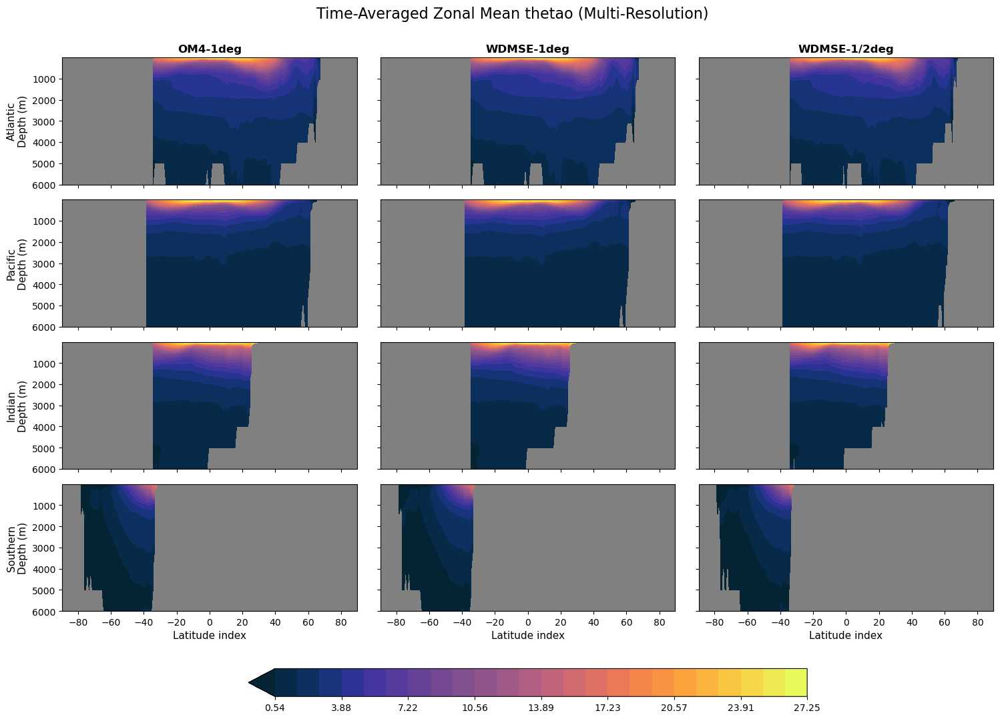


Generating OHC Zonal Mean Comparison (Multi-Resolution)...


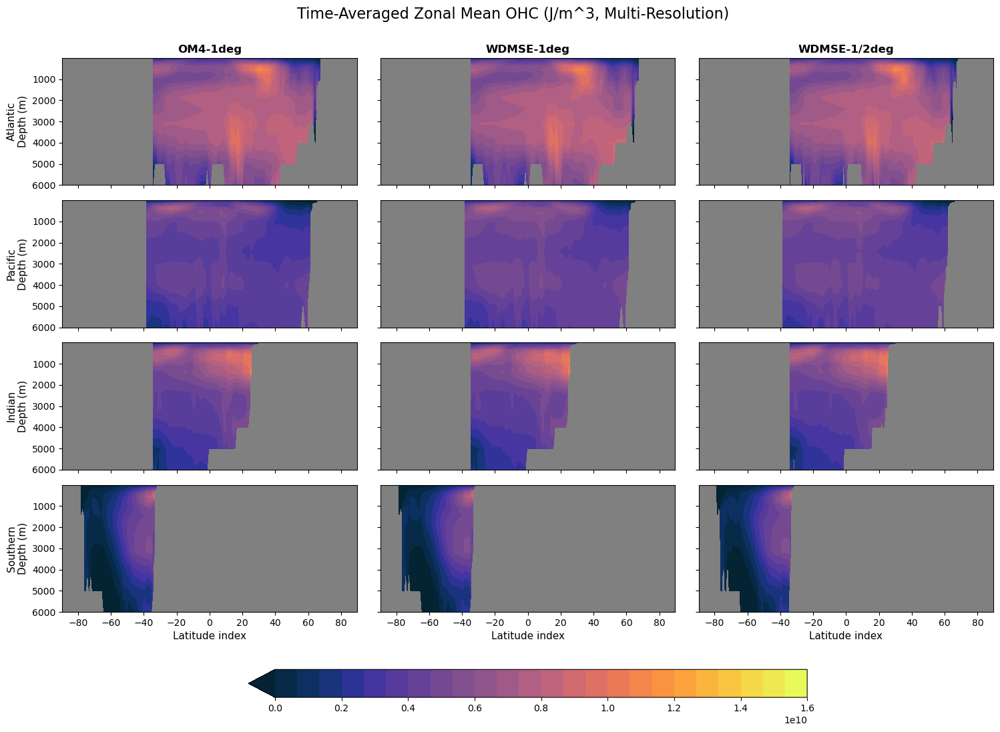


Generating Zonal Snapshot Comparison for thetao (Multi-Resolution)...


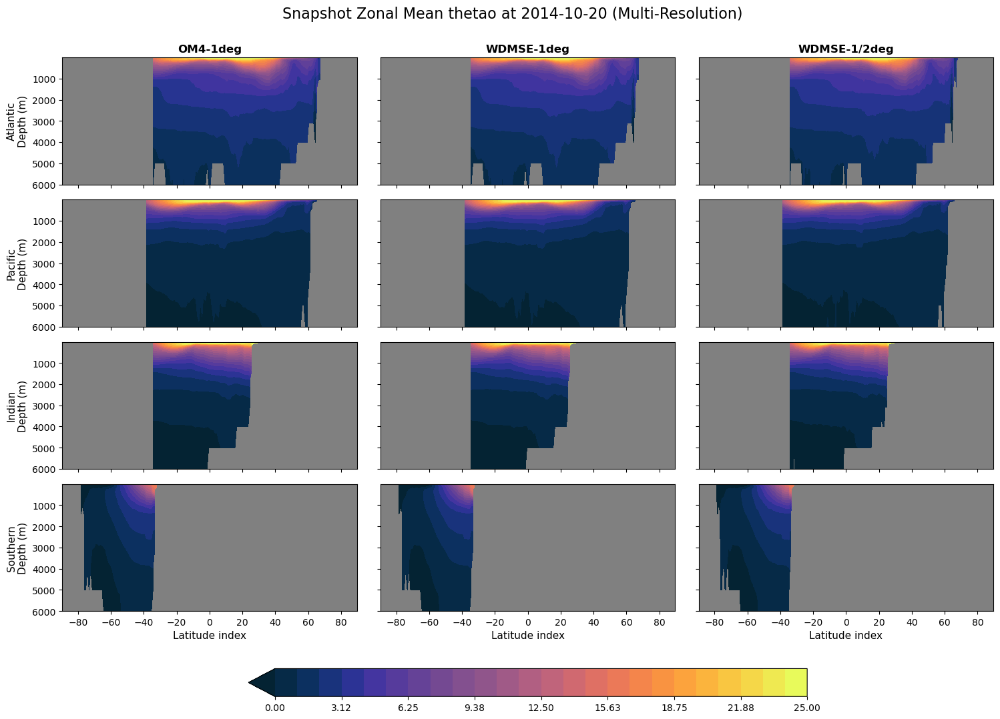

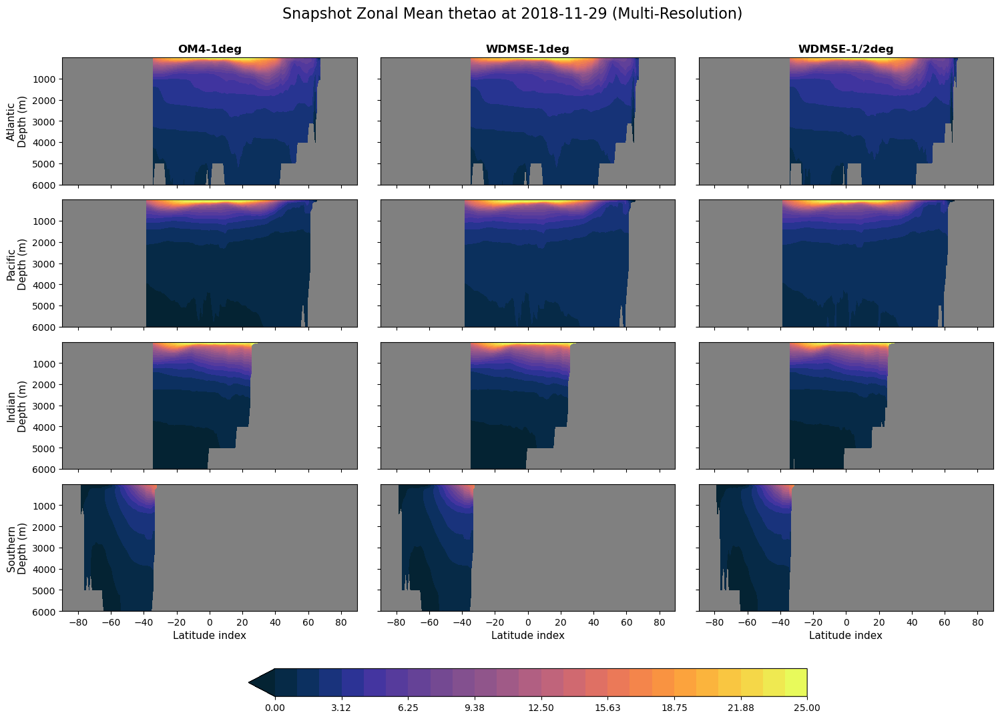

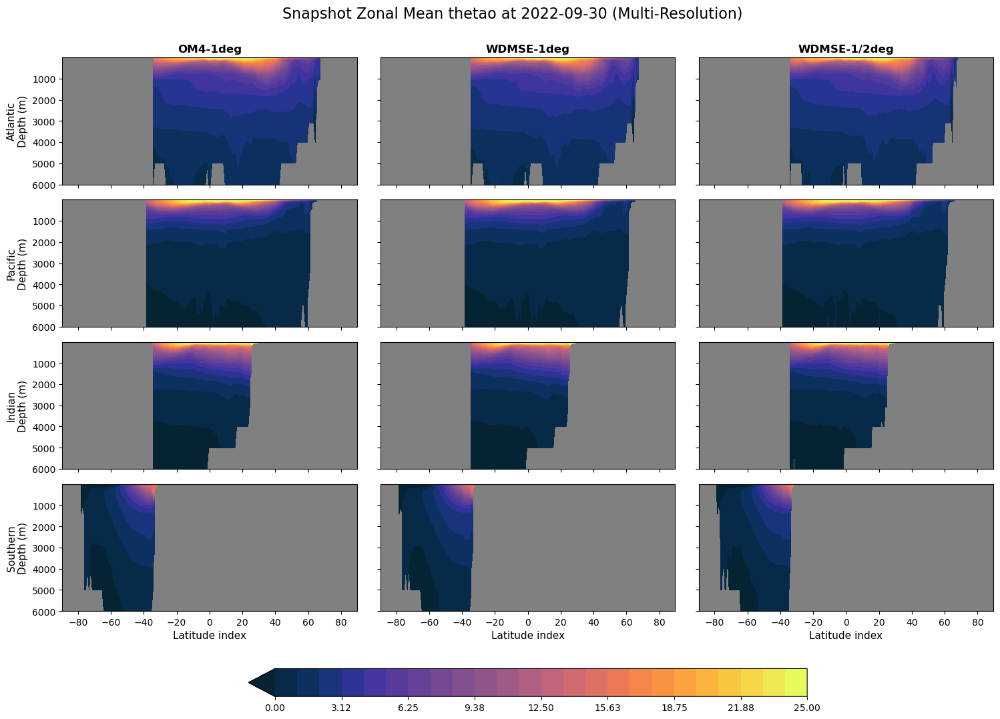


Generating OHC Zonal Snapshot Comparison (Multi-Resolution)...


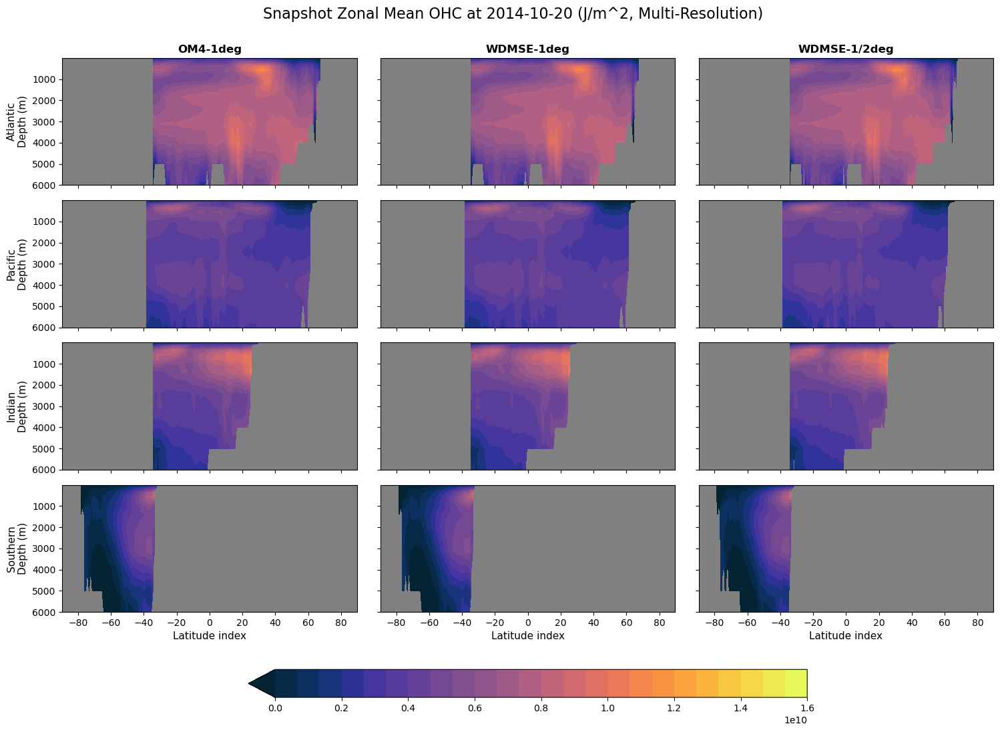

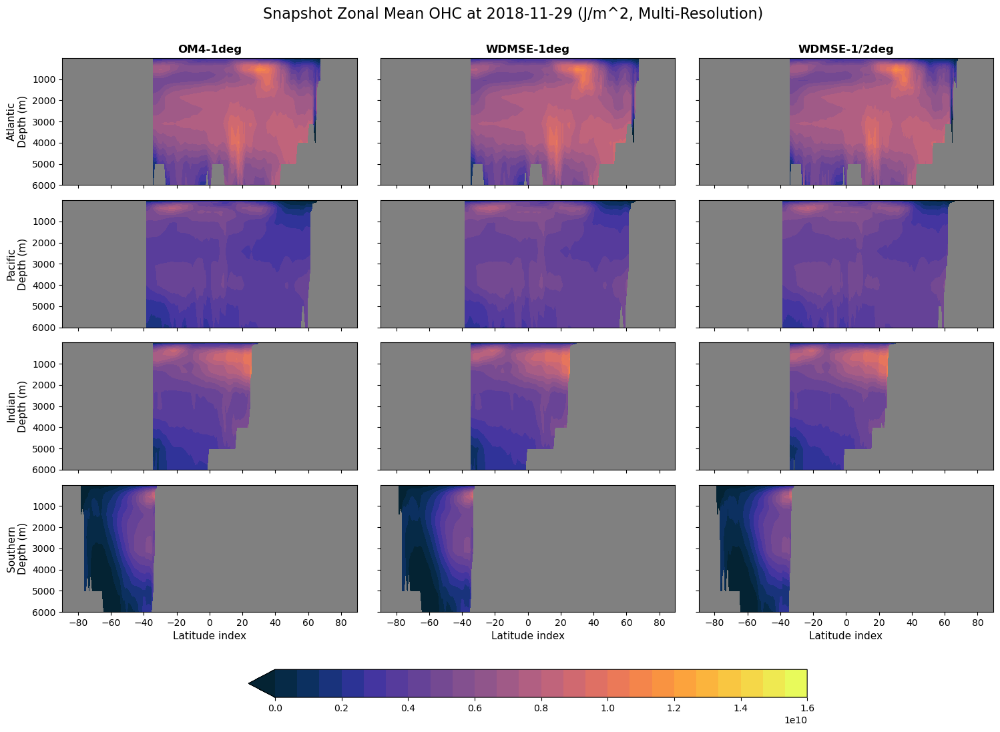

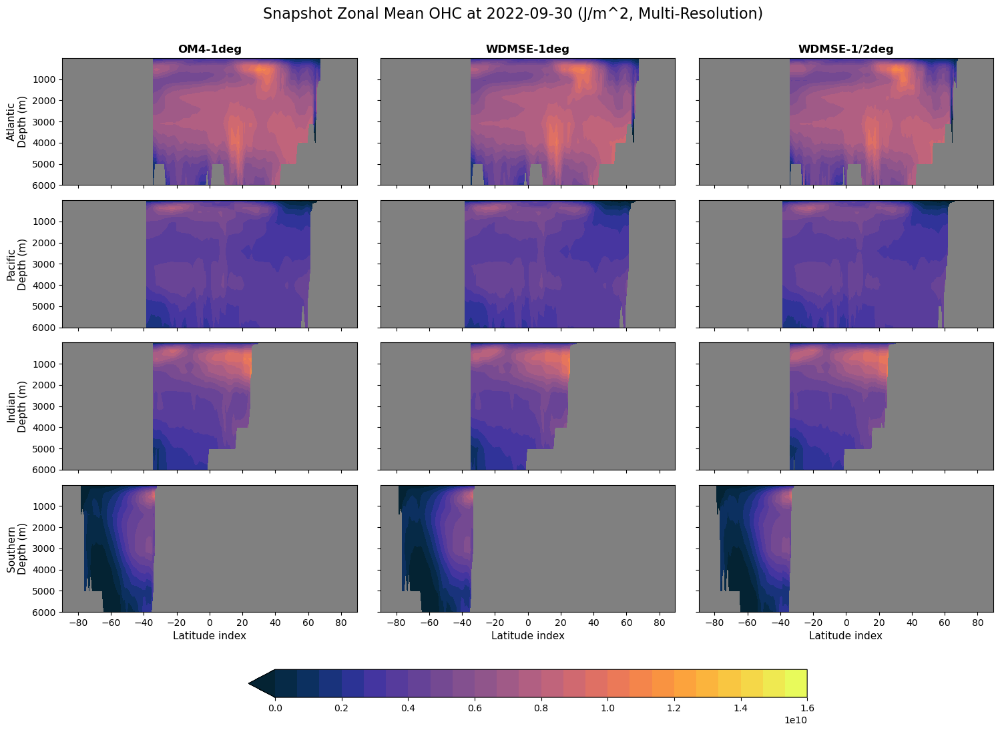

In [8]:
from functions import *
# --- Execution ---

plot_zonal_mean_comparison_together(
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks_list=masks_list,
    colorbar_fix=True
)


plot_ohc_zonal_mean_comparison_together(
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks_list=masks_list,
    colorbar_fix=True 
)


plot_zonal_snapshot_comparison_together(
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks_list=masks_list,
    time_indices = TIME_INDICES,
    colorbar_fix=True
)


plot_ohc_zonal_snapshot_comparison_together(
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks_list=masks_list,
    TIME_INDICES = TIME_INDICES,
    colorbar_fix=True
)

### Global Spatial Distribution Maps

Spatial maps of temperature and OHC at selected depth layers, comparing emulator predictions against truth.

**Settings:**
- **Variables:** `thetao` (temperature, units: °C) and OHC
- **Depth layers:** Surface (2.5m), 700m, 2000m for temperature; Surface (0-700m), Intermediate (700-2000m), Deep (2000-7000m) for OHC
- **Views:**
  1. Time-averaged global maps
  2. Snapshot global maps at time indices [0, 300, 580] (start, middle, end)
- **Colorbar:** Fixed across resolutions for direct comparison


Generating OHC Mean Comparison (Multi-Resolution)...


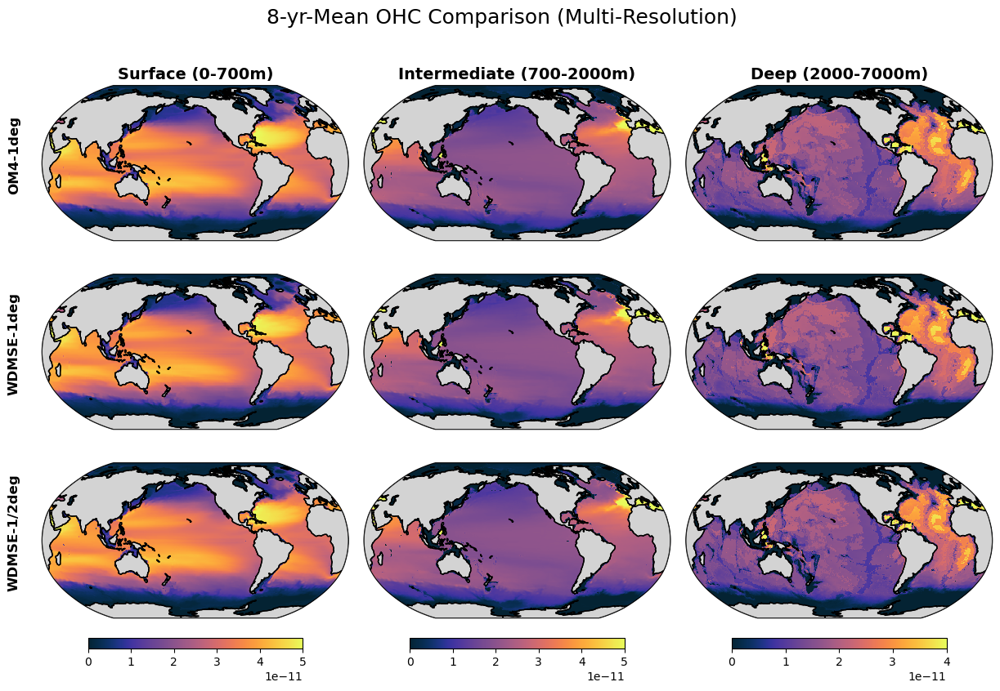


Generating Temperature Mean Comparison (Multi-Resolution)...


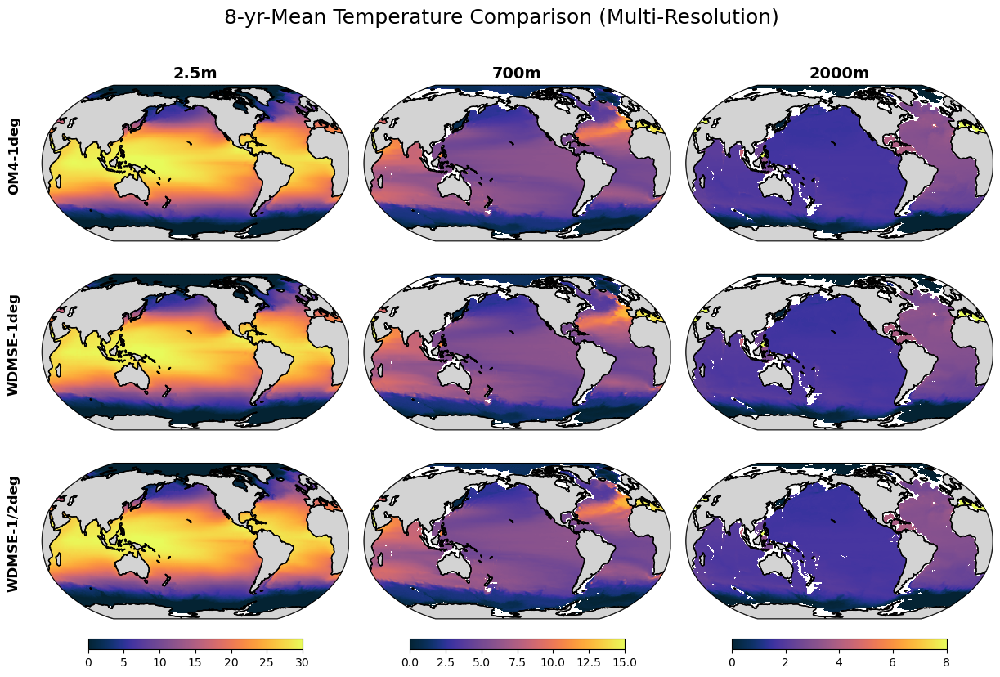


Generating Snapshot Comparison for Temperature (Multi-Resolution, Multi-Depth)...


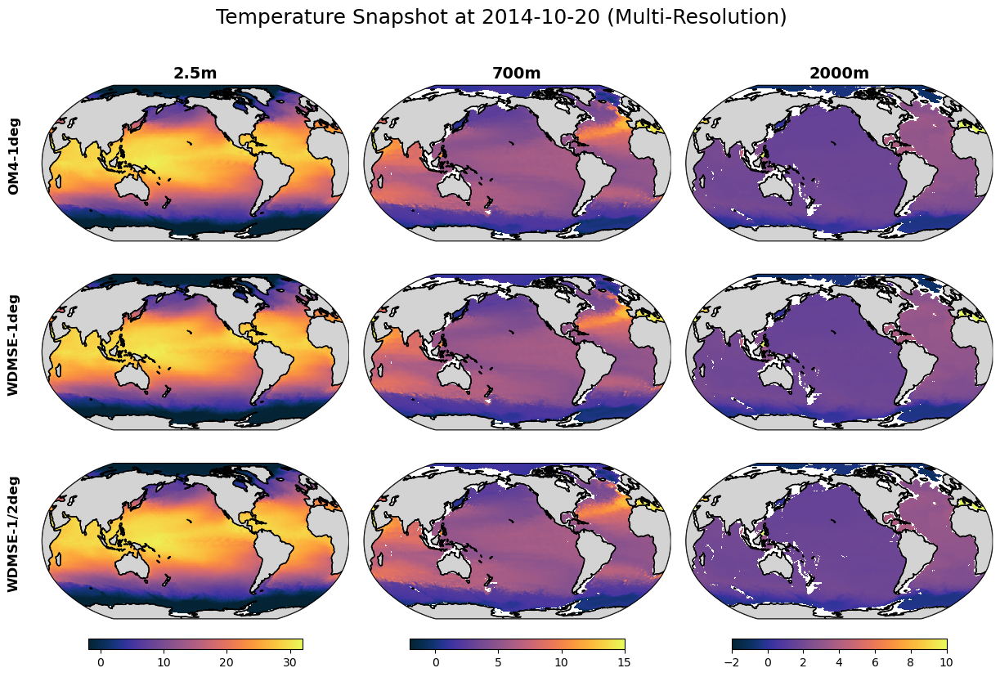

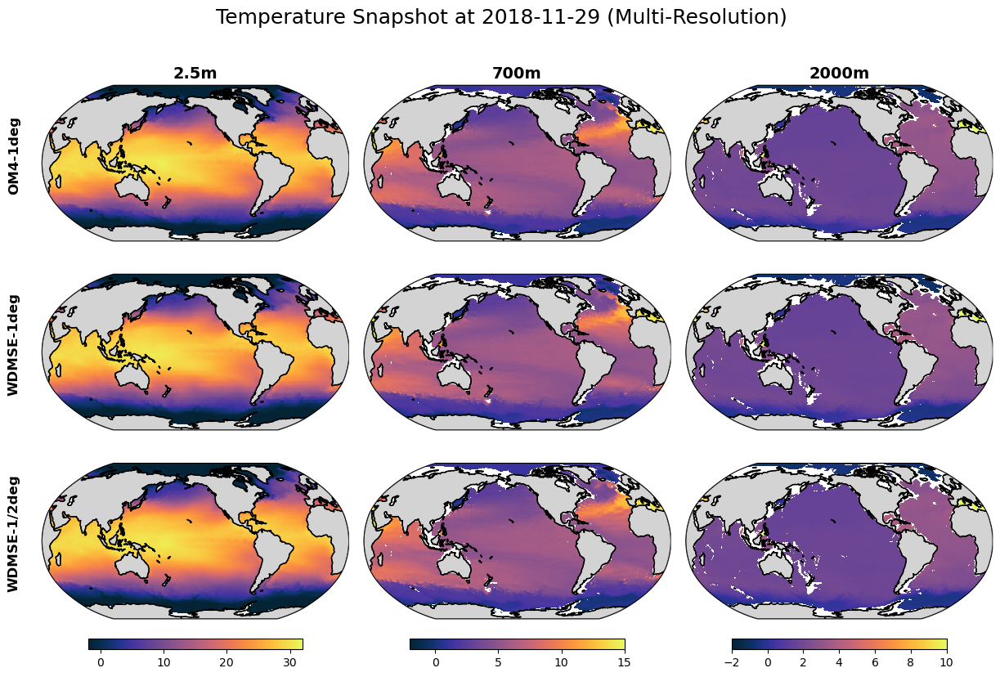

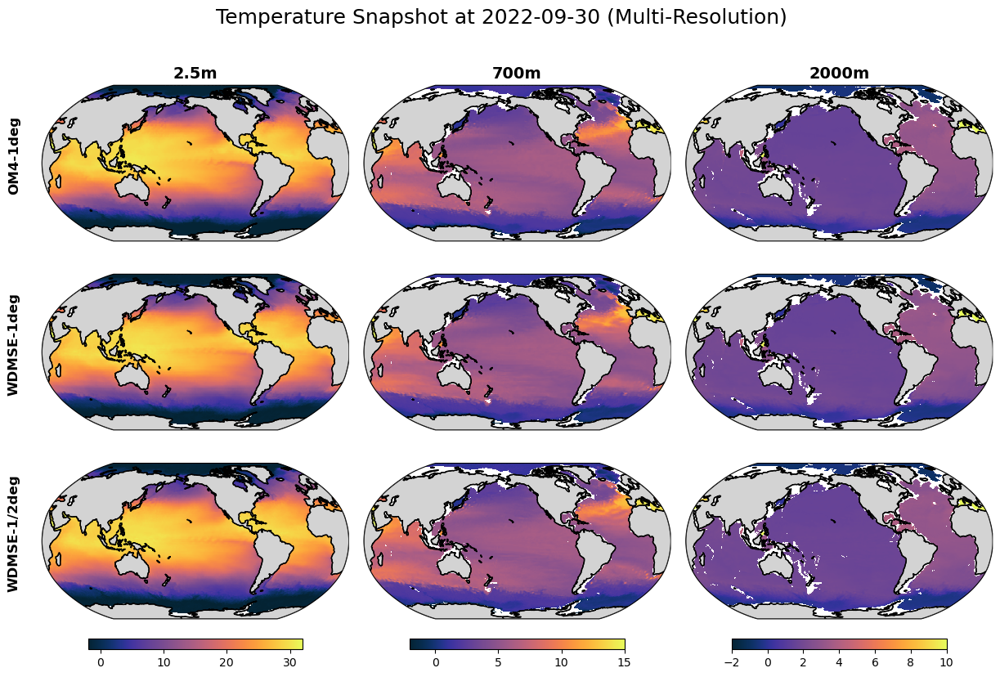


Generating OHC Snapshot Comparison (Multi-Resolution, Multi-Depth)...


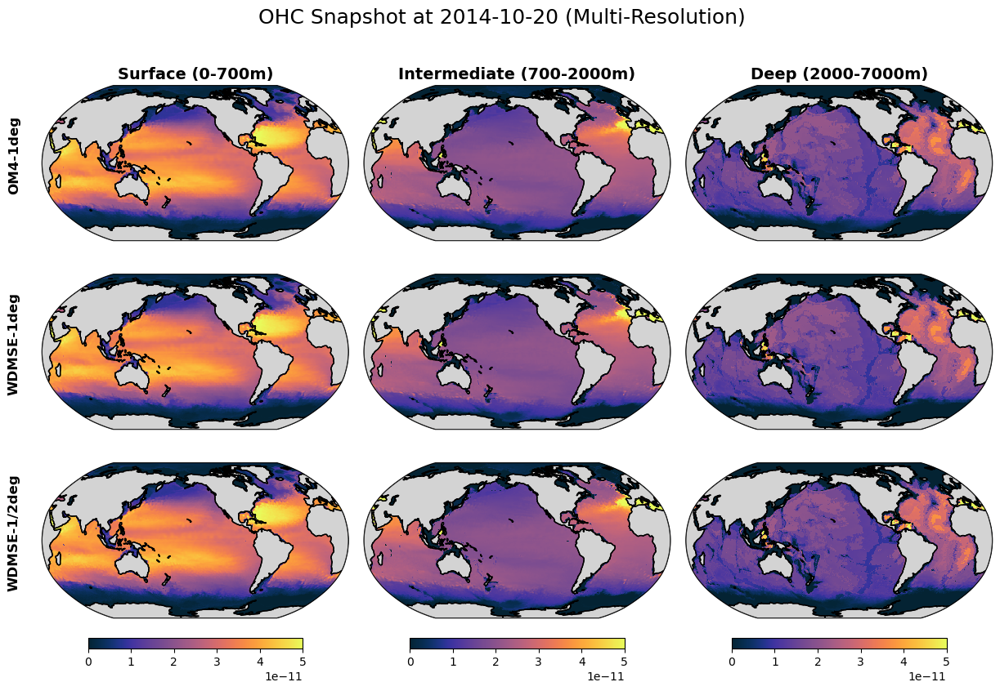

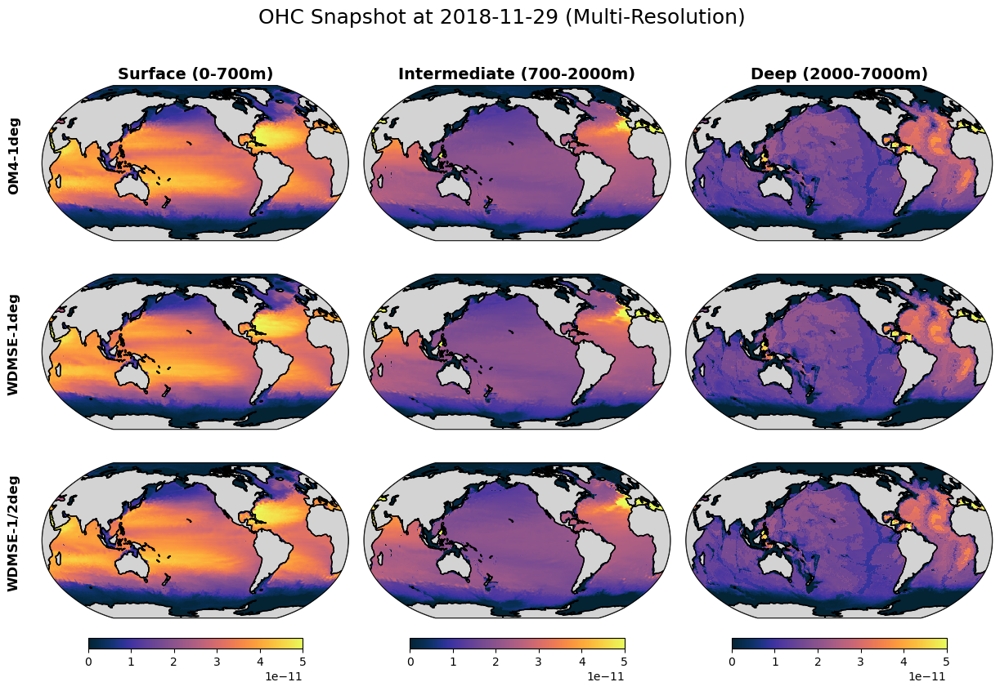

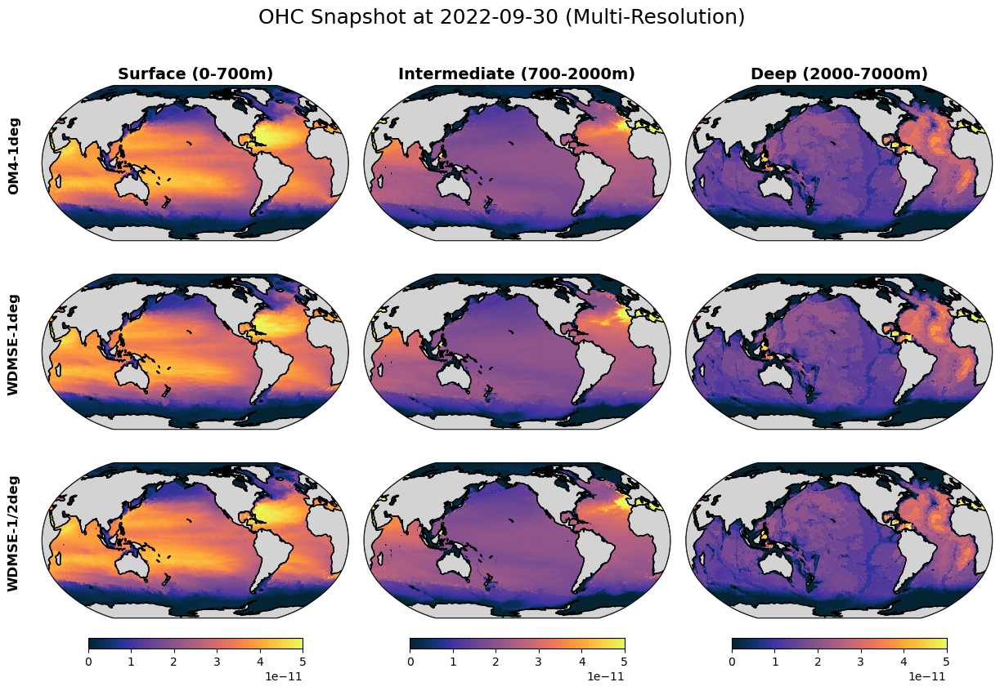

In [9]:
from functions import *


plot_ohc_mean_comparison_together(
    emulators_to_analyze,
    colorbar_fix=True
)

plot_temperature_mean_comparison_together(
    emulators_to_analyze,
    colorbar_fix=True
)

# --- Configuration ---
VARIABLE_TO_PLOT = 'thetao'  # Options: 'thetao', 'so', 'zos', 'uo', 'vo'

plot_snapshot_comparison_multidepth_together(
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_configs=DEPTH_LAYERS,  # Pass the entire list of depths here
    fix_colorbar=True
)

VARIABLE_TO_PLOT = 'thetao'

plot_ohc_snapshot_comparison_multidepth_together(
    emulators_to_analyze, 
    time_indices=TIME_INDICES,
    depth_configs=DEPTH_SLICES,  # Pass the list of depth slices
    colorbar_fix=True
)